# CrowdRoute Delhi — ML Pipeline

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/devansh-g10/CrowdSense/blob/main/notebooks/CrowdRoute_Delhi_ML_Pipeline.ipynb)


In [1]:
!pip install -q pandas numpy matplotlib seaborn scikit-learn duckdb pyarrow rapidfuzz

In [2]:
import pandas as pd

df = pd.read_csv("October-Delhi.csv")

print("Dataset Shape:", df.shape)
print("\nColumns:", df.columns.tolist())
print("\nFirst 5 Rows:")
print(df.head())
print("\nMissing Values:")
print(df.isnull().sum())
print("\nDataset Information:")
df.info()

Dataset Shape: (2559899, 9)

Columns: ['passenger_count', 'amount', 'vehicle_number', 'ticket_type_id', 'end_stop_name', 'route', 'start_stop_name', 'created_at', 'is_ac']

First 5 Rows:
   passenger_count  amount vehicle_number  ticket_type_id  \
0                1    22.0            NaN               1   
1                1     9.0      DL1PD6826               1   
2                1    13.5     DL51EV9760               1   
3                1    13.5            NaN               1   
4                1     9.0     DL51EV9810               1   

           end_stop_name    route       start_stop_name  \
0  Mahamaya Flyover West      8UP           Ali Village   
1            Crown Plaza   8ADOWN      Kalindi Kunj Bdr   
2             Clal Chowk    433UP          Andrews Ganj   
3            Ice Factory  208DOWN      West Patel Nagar   
4             Mallu Farm    516UP  Chhatarpur Extension   

                         created_at  is_ac  
0  2026-10-28 10:19:18.780611+05:30   True  
1

In [3]:
# Convert timestamp into Indian local time
df["created_at"] = pd.to_datetime(
    df["created_at"],
    format="mixed",
    errors="coerce",
    utc=True
).dt.tz_convert("Asia/Kolkata")

print("Invalid timestamps:", df["created_at"].isna().sum())
print("Start Date:", df["created_at"].min())
print("End Date:", df["created_at"].max())

print("\nTimestamp conversion completed!")

Invalid timestamps: 0
Start Date: 2026-10-01 00:00:01.796721+05:30
End Date: 2026-10-31 23:58:22.450250+05:30

Timestamp conversion completed!


In [4]:
print("Invalid Passenger Counts:",
      (df["passenger_count"] <= 0).sum())

print("Negative Fare:",
      (df["amount"] < 0).sum())

print("Same Boarding and Destination:",
      (df["start_stop_name"] == df["end_stop_name"]).sum())

print("Duplicate Candidates:",
      df.duplicated().sum())

print("Unique Routes:",
      df["route"].nunique())

print("Unique Vehicles:",
      df["vehicle_number"].nunique())

print("Total Recorded Passengers:",
      df["passenger_count"].sum())

Invalid Passenger Counts: 0
Negative Fare: 0
Same Boarding and Destination: 103
Duplicate Candidates: 0
Unique Routes: 2259
Unique Vehicles: 6809
Total Recorded Passengers: 2753606


In [5]:
# Extract useful time-based features
df["hour"] = df["created_at"].dt.hour.astype("Int8")

df["day_of_week"] = (
    df["created_at"].dt.dayofweek.astype("Int8")
)

df["is_weekend"] = df["day_of_week"] >= 5

df["time_slot"] = (
    df["created_at"].dt.hour * 2 +
    df["created_at"].dt.minute // 30
).astype("Int8")

df["has_vehicle"] = df["vehicle_number"].notna()

print("Feature engineering completed!")

display(df.head())

Feature engineering completed!


,passenger_count,amount,vehicle_number,ticket_type_id,end_stop_name,route,start_stop_name,created_at,is_ac,hour,day_of_week,is_weekend,time_slot,has_vehicle
0,1,22.0,NaN,1,Mahamaya Flyover West,8UP,Ali Village,2026-10-28 10:19:18.780611+05:30,True,10,2,False,20,False
1,1,9.0,DL1PD6826,1,Crown Plaza,8ADOWN,Kalindi Kunj Bdr,2026-10-28 10:19:29.989461+05:30,True,10,2,False,20,True
2,1,13.5,DL51EV9760,1,Clal Chowk,433UP,Andrews Ganj,2026-10-28 10:19:46.297108+05:30,True,10,2,False,20,True
3,1,13.5,NaN,1,Ice Factory,208DOWN,West Patel Nagar,2026-10-28 10:19:47.853905+05:30,True,10,2,False,20,False
4,1,9.0,DL51EV9810,1,Mallu Farm,516UP,Chhatarpur Extension,2026-10-28 10:19:48.525393+05:30,True,10,2,False,20,True


In [6]:
import gc

before = df.memory_usage(deep=True).sum() / 1024**2

category_columns = [
    "route",
    "vehicle_number",
    "start_stop_name",
    "end_stop_name"
]

for col in category_columns:
    df[col] = df[col].astype("category")

gc.collect()

after = df.memory_usage(deep=True).sum() / 1024**2

print(f"Memory Before: {before:.2f} MB")
print(f"Memory After: {after:.2f} MB")
print(f"Memory Saved: {before - after:.2f} MB")

Memory Before: 682.37 MB
Memory After: 124.32 MB
Memory Saved: 558.04 MB


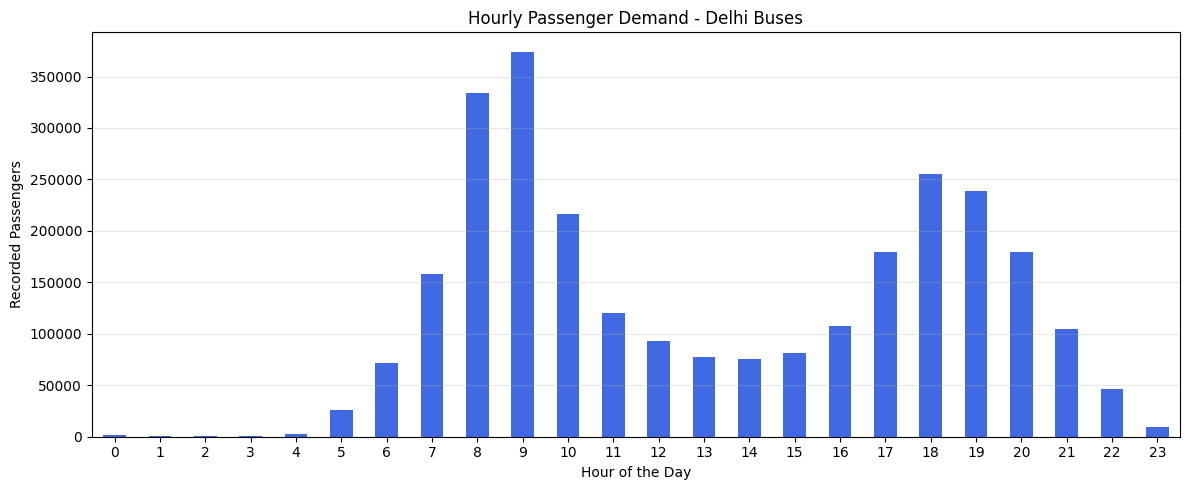

In [7]:
import matplotlib.pyplot as plt

hourly_demand = df.groupby("hour")["passenger_count"].sum()

plt.figure(figsize=(12, 5))

hourly_demand.plot(
    kind="bar",
    color="royalblue"
)

plt.title("Hourly Passenger Demand - Delhi Buses")
plt.xlabel("Hour of the Day")
plt.ylabel("Recorded Passengers")
plt.xticks(rotation=0)
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()
plt.close()

,total_passengers,number_of_days,average_daily_passengers
day_type,,,
Weekday,2147861,22,97630.05
Weekend,605745,9,67305.00


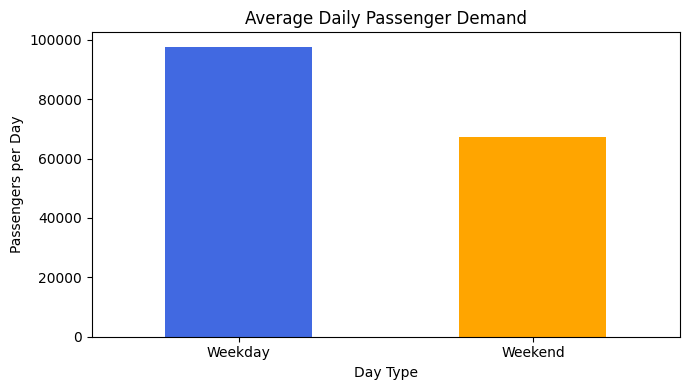

In [8]:
# Weekday vs Weekend daily demand

daily_demand = df.groupby(
    df["created_at"].dt.date
)["passenger_count"].sum().reset_index()

daily_demand.columns = ["date", "passengers"]

daily_demand["date"] = pd.to_datetime(daily_demand["date"])

daily_demand["day_type"] = daily_demand["date"].dt.dayofweek.map(
    lambda x: "Weekend" if x >= 5 else "Weekday"
)

day_analysis = daily_demand.groupby("day_type").agg(
    total_passengers=("passengers", "sum"),
    number_of_days=("date", "count"),
    average_daily_passengers=("passengers", "mean")
).round(2)

display(day_analysis)

day_analysis["average_daily_passengers"].plot(
    kind="bar",
    color=["royalblue", "orange"],
    figsize=(7, 4)
)

plt.title("Average Daily Passenger Demand")
plt.ylabel("Passengers per Day")
plt.xlabel("Day Type")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()
plt.close()

,passenger_count
route,
717AUP,27818
717ADOWN,27728
729DOWN,19009
729UP,18739
511AUP,18725
511ADOWN,16908
623UP,16884
623DOWN,16459
717BDOWN,16434


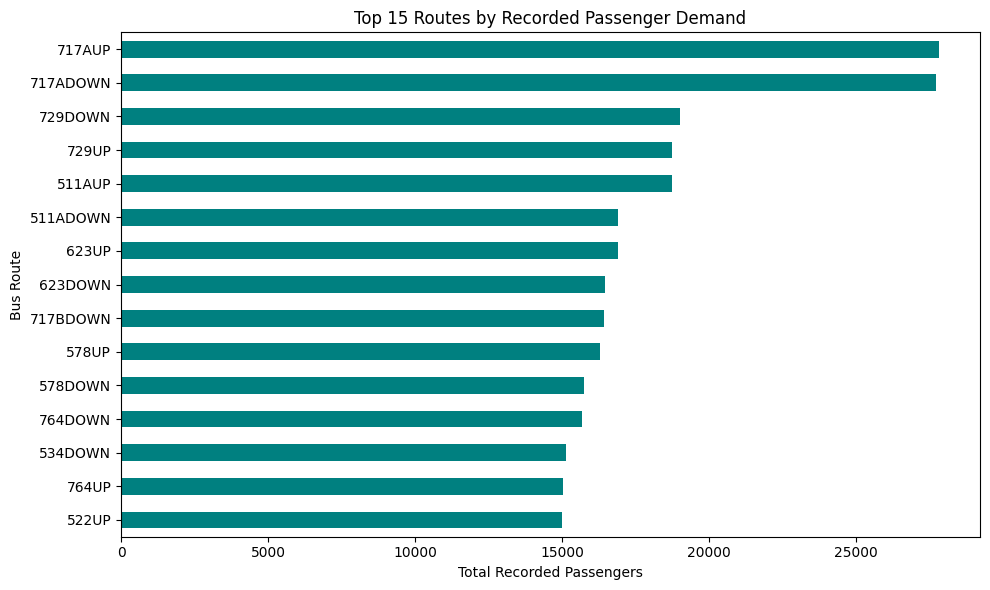

In [9]:
# Top routes by recorded passenger demand

route_demand = df.groupby(
    "route", observed=True
)["passenger_count"].sum().nlargest(15)

display(route_demand)

route_demand.sort_values().plot(
    kind="barh",
    figsize=(10, 6),
    color="teal"
)

plt.title("Top 15 Routes by Recorded Passenger Demand")
plt.xlabel("Total Recorded Passengers")
plt.ylabel("Bus Route")
plt.tight_layout()
plt.show()
plt.close()

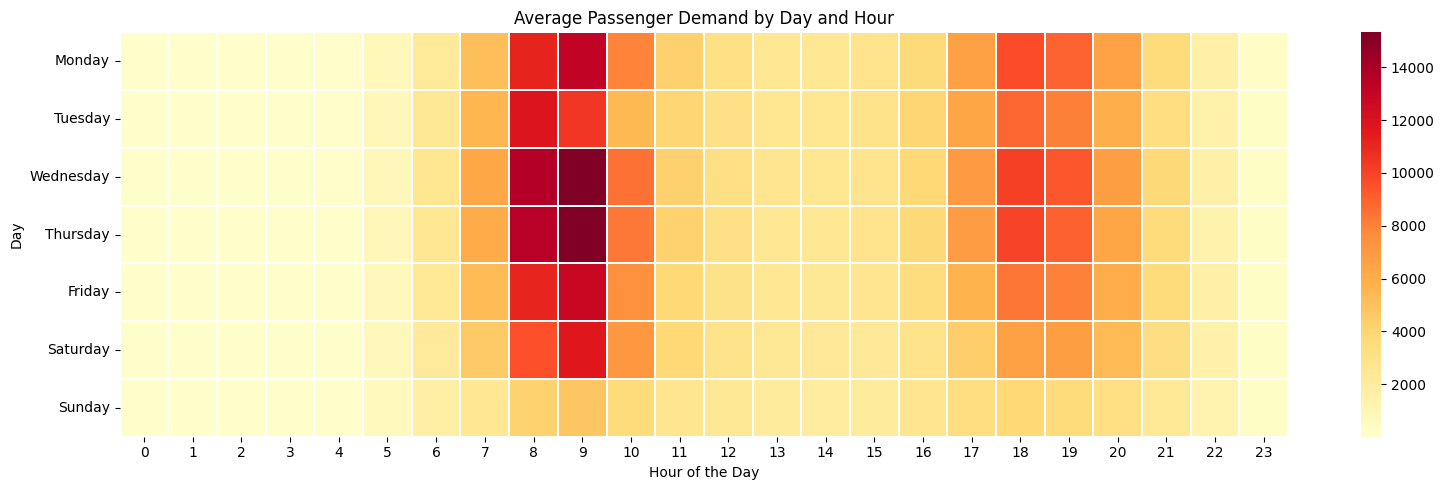

In [10]:
import seaborn as sns

# Passenger demand by day and hour

demand_heatmap = df.groupby(
    ["day_of_week", "hour"],
    observed=True
)["passenger_count"].sum().unstack(fill_value=0)

day_counts = daily_demand["date"].dt.dayofweek.value_counts()

demand_heatmap = demand_heatmap.div(day_counts, axis=0)

demand_heatmap = demand_heatmap.reindex(range(7))

demand_heatmap.index = [
    "Monday", "Tuesday", "Wednesday",
    "Thursday", "Friday", "Saturday", "Sunday"
]

plt.figure(figsize=(16, 5))

sns.heatmap(
    demand_heatmap,
    cmap="YlOrRd",
    linewidths=0.2
)

plt.title("Average Passenger Demand by Day and Hour")
plt.xlabel("Hour of the Day")
plt.ylabel("Day")
plt.tight_layout()
plt.show()
plt.close()

In [11]:
# Check vehicle information coverage

vehicle_coverage = df.groupby("has_vehicle").agg(
    ticket_records=("passenger_count", "size"),
    total_passengers=("passenger_count", "sum")
)

vehicle_coverage.index = vehicle_coverage.index.map({
    True: "Vehicle Available",
    False: "Vehicle Missing"
})

vehicle_coverage["ticket_percentage"] = (
    vehicle_coverage["ticket_records"] / len(df) * 100
).round(2)

display(vehicle_coverage)

print("Vehicle coverage analysis completed!")

,ticket_records,total_passengers,ticket_percentage
has_vehicle,,,
Vehicle Missing,1242167,1331588,48.52
Vehicle Available,1317732,1422018,51.48


Vehicle coverage analysis completed!


In [12]:
from pathlib import Path

print("Available dataset files:\n")

for path in Path("/content").iterdir():
    if path.is_file():
        print(
            path.name,
            "|",
            round(path.stat().st_size / 1024**2, 2),
            "MB"
        )
    elif path.is_dir() and not path.name.startswith("."):
        print("Folder:", path.name)

Available dataset files:

stops.txt | 0.41 MB
October-Delhi.csv | 276.58 MB
feed_info.txt | 0.0 MB
routes.txt | 0.21 MB
agency.txt | 0.0 MB
calendar.txt | 0.0 MB
stop_times.txt | 116.1 MB
shapes.txt | 40.02 MB
trips.txt | 4.99 MB
Folder: sample_data


In [13]:
import duckdb
from pathlib import Path

GTFS_PATH = Path("/content")

con = duckdb.connect("/content/crowdroute.duckdb")

con.execute("SET memory_limit = '1GB'")
con.execute("SET threads = 2")
con.execute("SET temp_directory = '/content/duckdb_temp'")

print("DuckDB connected successfully!")
print("GTFS path:", GTFS_PATH)

DuckDB connected successfully!
GTFS path: /content


In [14]:
gtfs_files = {
    "gtfs_stops": "stops.txt",
    "gtfs_routes": "routes.txt",
    "gtfs_trips": "trips.txt",
    "gtfs_stop_times": "stop_times.txt",
    "gtfs_calendar": "calendar.txt"
}

for table, filename in gtfs_files.items():

    path = GTFS_PATH / filename

    if not path.exists():
        raise FileNotFoundError(path)

    con.execute(f"""
        CREATE OR REPLACE VIEW {table} AS
        SELECT *
        FROM read_csv_auto(
            '{path}',
            header=True,
            all_varchar=True
        )
    """)

    print(f"{filename}: Connected")

print("\nGTFS integration successful!")

stops.txt: Connected
routes.txt: Connected
trips.txt: Connected
stop_times.txt: Connected
calendar.txt: Connected

GTFS integration successful!


In [15]:
for table in gtfs_files:

    print("\n" + "=" * 50)
    print("TABLE:", table)

    columns = con.execute(
        f"DESCRIBE {table}"
    ).df()

    print("Columns:", columns["column_name"].tolist())

    display(
        con.execute(
            f"SELECT * FROM {table} LIMIT 3"
        ).df()
    )


TABLE: gtfs_stops
Columns: ['stop_id', 'stop_code', 'stop_name', 'stop_lat', 'stop_lon']


,stop_id,stop_code,stop_name,stop_lat,stop_lon
0,1,9CE15308,Rohini Sec 22 Terminal,28.71797103184126,77.06389993096785
1,2,49FEABBE,Lakhhi Ram Park,28.71353301246467,77.06030224263961
2,4470,211FB561,Aman Vihar,28.71131299254109,77.06322815655092



TABLE: gtfs_routes
Columns: ['agency_id', 'route_id', 'route_long_name', 'route_short_name', 'route_desc', 'route_type']


,agency_id,route_id,route_long_name,route_short_name,route_desc,route_type
0,DIMTS,1,102ADOWN,102ADOWN,Rohini Sec 22 Terminal to Azadpur Terminal,3
1,DIMTS,4,102AUP,102AUP,Azadpur Terminal to Rohini Sec 22 Terminal,3
2,DIMTS,5,102DOWN,102DOWN,Rohini Sec 22 Terminal to Old Delhi Railway St...,3



TABLE: gtfs_trips
Columns: ['route_id', 'service_id', 'trip_id', 'trip_headsign', 'trip_short_name', 'direction_id', 'block_id', 'shape_id', 'wheelchair_accessible', 'bikes_allowed']


,route_id,service_id,trip_id,trip_headsign,trip_short_name,direction_id,block_id,shape_id,wheelchair_accessible,bikes_allowed
0,1000,1,1000_FULL_06_10,Kashmere Gate City Bus Terminal,None,None,None,shp_3_1561,0,0
1,1000,1,1000_FULL_07_50,Kashmere Gate City Bus Terminal,None,None,None,shp_3_1561,0,0
2,1000,1,1000_FULL_15_10,Kashmere Gate City Bus Terminal,None,None,None,shp_3_1561,0,0



TABLE: gtfs_stop_times
Columns: ['trip_id', 'arrival_time', 'departure_time', 'stop_id', 'stop_sequence', 'fare_stage', 'stop_dist']


,trip_id,arrival_time,departure_time,stop_id,stop_sequence,fare_stage,stop_dist
0,1_FULL_06_05,06:05:00,06:05:00,1,0,0,None
1,1_FULL_06_05,06:07:00,06:07:00,2,1,0,None
2,1_FULL_06_05,06:08:16,06:08:16,4470,2,0,None



TABLE: gtfs_calendar
Columns: ['service_id', 'monday', 'tuesday', 'wednesday', 'thursday', 'friday', 'saturday', 'sunday', 'start_date', 'end_date']


,service_id,monday,tuesday,wednesday,thursday,friday,saturday,sunday,start_date,end_date
0,1,1,1,1,1,1,1,1,20250101,20400101


In [16]:
gtfs_summary = []

for table in gtfs_files:

    count = con.execute(
        f"SELECT COUNT(*) FROM {table}"
    ).fetchone()[0]

    gtfs_summary.append({
        "Table": table,
        "Total Records": count
    })

display(pd.DataFrame(gtfs_summary))

,Table,Total Records
0,gtfs_stops,6862
1,gtfs_routes,2574
2,gtfs_trips,80357
3,gtfs_stop_times,2737136
4,gtfs_calendar,1


In [17]:
import re

def normalize_route(value):
    if pd.isna(value):
        return ""

    return re.sub(
        r"\s+", "", str(value).upper().strip()
    )


# Only unique ticket route names
ticket_routes = pd.DataFrame({
    "ticket_route": df["route"].unique()
})

ticket_routes["route_key"] = (
    ticket_routes["ticket_route"].map(normalize_route)
)

# Load small GTFS routes table
routes = con.execute(
    "SELECT * FROM gtfs_routes"
).df()

print("Ticket route columns:")
display(ticket_routes.head(10))

print("\nGTFS route columns:")
display(routes.head(10))

print("\nUnique ticket route labels:", len(ticket_routes))
print("GTFS route records:", len(routes))

Ticket route columns:


,ticket_route,route_key
0,8UP,8UP
1,8ADOWN,8ADOWN
2,433UP,433UP
3,208DOWN,208DOWN
4,516UP,516UP
5,448DOWN,448DOWN
6,114UP,114UP
7,717AUP,717AUP
8,128DOWN,128DOWN
9,772UP,772UP



GTFS route columns:


,agency_id,route_id,route_long_name,route_short_name,route_desc,route_type
0,DIMTS,1,102ADOWN,102ADOWN,Rohini Sec 22 Terminal to Azadpur Terminal,3
1,DIMTS,4,102AUP,102AUP,Azadpur Terminal to Rohini Sec 22 Terminal,3
2,DIMTS,5,102DOWN,102DOWN,Rohini Sec 22 Terminal to Old Delhi Railway St...,3
3,DIMTS,6,102LSTLDOWN,102LSTLDOWN,Kanjhawala Village (T) to Rani Khera Depot 1,3
4,DIMTS,7,102LSTLUP,102LSTLUP,Rani Khera Depot 1 to Kanjhawala Village (T),3
5,DIMTS,8,102STLDOWN,102STLDOWN,Rohini Sec 22 Terminal to Rani Khera Depot 3,3
6,DIMTS,9,102STLUP,102STLUP,Rani Khera Depot 3 to Rohini Sec 22 Terminal,3
7,DIMTS,10,102UP,102UP,Old Delhi Railway Station (T) to Rohini Sec 22...,3
8,DIMTS,14,103LSTLDOWN,103LSTLDOWN,Rani Khera Depot 1 to Mubarakpur Dabas Village,3
9,DIMTS,15,103LSTLUP,103LSTLUP,Mubarakpur Dabas Village to Rani Khera Depot 1,3



Unique ticket route labels: 2259
GTFS route records: 2574


In [18]:
routes["route_key"] = (
    routes["route_short_name"].map(normalize_route)
)

route_candidates = routes[
    ["route_id", "route_key"]
].drop_duplicates()

# Remove empty route names
route_candidates = route_candidates[
    route_candidates["route_key"] != ""
]

route_mapping = ticket_routes.merge(
    route_candidates,
    on="route_key",
    how="left"
)

route_match_counts = route_mapping.groupby(
    "ticket_route",
    observed=True
)["route_id"].nunique()

print("Total Ticket Route Labels:", len(ticket_routes))

print("Unique Match:",
      (route_match_counts == 1).sum())

print("Multiple Match:",
      (route_match_counts > 1).sum())

print("Unmatched:",
      (route_match_counts == 0).sum())

print("\nSample Route Mapping:")
display(route_mapping.head(15))

Total Ticket Route Labels: 2259
Unique Match: 1980
Multiple Match: 0
Unmatched: 279

Sample Route Mapping:


,ticket_route,route_key,route_id
0,8UP,8UP,2393
1,8ADOWN,8ADOWN,2390
2,433UP,433UP,1932
3,208DOWN,208DOWN,1698
4,516UP,516UP,2014
5,448DOWN,448DOWN,1957
6,114UP,114UP,72
7,717AUP,717AUP,2171
8,128DOWN,128DOWN,97
9,772UP,772UP,779


In [19]:
matched_routes = route_match_counts[
    route_match_counts == 1
].index

ambiguous_routes = route_match_counts[
    route_match_counts > 1
].index

unmatched_routes = route_match_counts[
    route_match_counts == 0
].index

route_record_counts = df["route"].value_counts()

coverage = pd.DataFrame({
    "Status": [
        "Unique Match",
        "Multiple Match",
        "Unmatched"
    ],
    "Route Labels": [
        len(matched_routes),
        len(ambiguous_routes),
        len(unmatched_routes)
    ],
    "Ticket Records": [
        route_record_counts.reindex(
            matched_routes, fill_value=0
        ).sum(),

        route_record_counts.reindex(
            ambiguous_routes, fill_value=0
        ).sum(),

        route_record_counts.reindex(
            unmatched_routes, fill_value=0
        ).sum()
    ]
})

coverage["Coverage_Percentage"] = (
    coverage["Ticket Records"] / len(df) * 100
).round(2)

display(coverage)

print("\nSample unmatched routes:")
print(unmatched_routes.tolist()[:20])

print("\nSample ambiguous routes:")
print(ambiguous_routes.tolist()[:20])

,Status,Route Labels,Ticket Records,Coverage_Percentage
0,Unique Match,1980,2514677,98.23
1,Multiple Match,0,0,0.00
2,Unmatched,279,45222,1.77



Sample unmatched routes:
['0118EXT(NS)UP', '0261(NS)UP', '0405(NS)DOWN', '0405(NS)UP', '0419(NS)DOWN', '0419(NS)UP', '0502(NS)DOWN', '0502(NS)UP', '0543A(NS)DOWN', '0604(NS)DOWN', '0604(NS)UP', '072(NS)UP', '0TMS(-)(NS)DOWN', '105STLDOWN', '105STLUP', '108ADOWN', '108AUP', '109ADOWN', '109AUP', '112ADOWN']

Sample ambiguous routes:
[]


In [20]:
valid_route_mapping = route_mapping.loc[
    route_mapping["ticket_route"].isin(matched_routes)
    & route_mapping["route_id"].notna(),
    ["ticket_route", "route_id"]
].drop_duplicates()

con.register("route_mapping_input", valid_route_mapping)

con.execute("""
    CREATE OR REPLACE TABLE route_lookup AS
    SELECT
        CAST(ticket_route AS VARCHAR) AS ticket_route,
        CAST(route_id AS VARCHAR) AS route_id
    FROM route_mapping_input
""")

con.unregister("route_mapping_input")

print("Route lookup created successfully!")

print("Mapped routes:",
      con.execute("""
          SELECT COUNT(*) FROM route_lookup
      """).fetchone()[0])

Route lookup created successfully!
Mapped routes: 1980


In [21]:
con.execute("""
    CREATE OR REPLACE MACRO normalize_stop(x) AS
        TRIM(
            REGEXP_REPLACE(
                UPPER(CAST(x AS VARCHAR)),
                '[^A-Z0-9]+',
                ' ',
                'g'
            )
        )
""")

con.execute("""
    CREATE OR REPLACE TABLE stop_lookup AS
    SELECT
        stop_id,
        stop_name,
        normalize_stop(stop_name) AS stop_key,
        TRY_CAST(stop_lat AS DOUBLE) AS latitude,
        TRY_CAST(stop_lon AS DOUBLE) AS longitude
    FROM gtfs_stops
    WHERE stop_id IS NOT NULL
""")

print("Stop lookup created successfully!")

display(con.execute("""
    SELECT * FROM stop_lookup LIMIT 10
""").df())

print("Total stops:",
      con.execute("""
          SELECT COUNT(*) FROM stop_lookup
      """).fetchone()[0])

Stop lookup created successfully!


,stop_id,stop_name,stop_key,latitude,longitude
0,1,Rohini Sec 22 Terminal,ROHINI SEC 22 TERMINAL,28.717971,77.063900
1,2,Lakhhi Ram Park,LAKHHI RAM PARK,28.713533,77.060302
2,4470,Aman Vihar,AMAN VIHAR,28.711313,77.063228
3,4087,Shiv Chowk Rohini Sec 20,SHIV CHOWK ROHINI SEC 20,28.709669,77.067154
4,4086,Rohini Sec 20 / 21 Pocket 9,ROHINI SEC 20 21 POCKET 9,28.713825,77.070708
5,3,Rohini Sec21,ROHINI SEC21,28.718700,77.069600
6,4,Rohini Sec 20/21/22 Crossing,ROHINI SEC 20 21 22 CROSSING,28.720084,77.068825
7,5,Police Station Begumpur,POLICE STATION BEGUMPUR,28.723037,77.071410
8,6,Poothkalan More,POOTHKALAN MORE,28.721174,77.078079
9,6946,Rohini Sec 23 Pkt 3 / Rohini Sec 23 Pocket 2,ROHINI SEC 23 PKT 3 ROHINI SEC 23 POCKET 2,28.720239,77.079493


Total stops: 6862


In [24]:
# Reset and optimize DuckDB configurations to prevent OOM
con.execute("SET memory_limit = '1.8GB'")
con.execute("SET max_memory = '1.5GB'")
con.execute("SET threads = 1")  # Limit threads to reduce memory overhead per thread
con.execute("SET preserve_insertion_order = false")

print("Building tables with streaming constraints...")

# Create sorted stop times view/table first to avoid complex on-the-fly ordering within LIST()
con.execute("""
    CREATE OR REPLACE TABLE sorted_stop_times AS
    SELECT
        trip_id,
        stop_id,
        CAST(stop_sequence AS INTEGER) as seq
    FROM gtfs_stop_times
    ORDER BY trip_id, seq
""")

# Perform the pattern aggregation on the pre-sorted structure
con.execute("""
    CREATE OR REPLACE TABLE trip_patterns AS
    SELECT
        t.route_id,
        s.trip_id,
        LIST(s.stop_id) AS stop_pattern,
        COUNT(*) AS stop_count
    FROM sorted_stop_times s
    JOIN gtfs_trips t ON t.trip_id = s.trip_id
    GROUP BY
        t.route_id,
        s.trip_id
    HAVING COUNT(*) >= 2
""")

# Drop the sorted temp table to free memory
con.execute("DROP TABLE sorted_stop_times")

# Create distinct route patterns from trip patterns
con.execute("""
    CREATE OR REPLACE TABLE route_patterns AS
    SELECT
        ROW_NUMBER() OVER (
            ORDER BY route_id, representative_trip_id
        ) AS pattern_id,
        *
    FROM (
        SELECT
            route_id,
            stop_pattern,
            MIN(trip_id) AS representative_trip_id,
            COUNT(*) AS scheduled_trips,
            MAX(stop_count) AS stop_count
        FROM trip_patterns
        GROUP BY
            route_id,
            stop_pattern
    ) p
""")

print("Route patterns created successfully!")

display(con.execute("""
    SELECT
        pattern_id,
        route_id,
        representative_trip_id,
        scheduled_trips,
        stop_count
    FROM route_patterns
    LIMIT 10
""").df())

print("Total route patterns:",
      con.execute("""
          SELECT COUNT(*) FROM route_patterns
      """).fetchone()[0])

Building tables with streaming constraints...


FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

Route patterns created successfully!


,pattern_id,route_id,representative_trip_id,scheduled_trips,stop_count
0,1,1,1_FULL_06_05,16,36
1,2,10,10_FULL_07_45,16,67
2,3,100,100_FULL_07_36,20,37
3,4,1000,1000_FULL_06_10,4,64
4,5,1000,1000_SHORT_11_05,4,30
5,6,1001,1001_FULL_07_50,10,61
6,7,1001,1001_SHORT_07_45,1,45
7,8,1001,1001_SHORT_08_05,2,48
8,9,1002,1002_FULL_07_15,16,44
9,10,1002,1002_SHORT_14_20,4,15


Total route patterns: 3498


In [25]:
con.execute("""
    CREATE OR REPLACE TABLE route_stop_sequence AS

    SELECT
        p.pattern_id,
        p.route_id,
        s.stop_id,
        l.stop_name,
        l.stop_key,

        ROW_NUMBER() OVER (
            PARTITION BY p.pattern_id
            ORDER BY CAST(s.stop_sequence AS INTEGER)
        ) - 1 AS stop_sequence,

        l.latitude,
        l.longitude

    FROM route_patterns p

    JOIN gtfs_stop_times s
        ON p.representative_trip_id = s.trip_id

    JOIN stop_lookup l
        ON s.stop_id = l.stop_id
""")

print("Route stop sequences generated!")

display(con.execute("""
    SELECT *
    FROM route_stop_sequence
    ORDER BY pattern_id, stop_sequence
    LIMIT 20
""").df())

print("Total sequence records:",
      con.execute("""
          SELECT COUNT(*) FROM route_stop_sequence
      """).fetchone()[0])

Route stop sequences generated!


,pattern_id,route_id,stop_id,stop_name,stop_key,stop_sequence,latitude,longitude
0,1,1,1,Rohini Sec 22 Terminal,ROHINI SEC 22 TERMINAL,0,28.717971,77.063900
1,1,1,2,Lakhhi Ram Park,LAKHHI RAM PARK,1,28.713533,77.060302
2,1,1,4470,Aman Vihar,AMAN VIHAR,2,28.711313,77.063228
3,1,1,4087,Shiv Chowk Rohini Sec 20,SHIV CHOWK ROHINI SEC 20,3,28.709669,77.067154
4,1,1,4086,Rohini Sec 20 / 21 Pocket 9,ROHINI SEC 20 21 POCKET 9,4,28.713825,77.070708
5,1,1,3,Rohini Sec21,ROHINI SEC21,5,28.718700,77.069600
6,1,1,4,Rohini Sec 20/21/22 Crossing,ROHINI SEC 20 21 22 CROSSING,6,28.720084,77.068825
7,1,1,5,Police Station Begumpur,POLICE STATION BEGUMPUR,7,28.723037,77.071410
8,1,1,6,Poothkalan More,POOTHKALAN MORE,8,28.721174,77.078079
9,1,1,6946,Rohini Sec 23 Pkt 3 / Rohini Sec 23 Pocket 2,ROHINI SEC 23 PKT 3 ROHINI SEC 23 POCKET 2,9,28.720239,77.079493


Total sequence records: 109660


In [26]:
con.register("ticket_input", df)

con.execute("""
    CREATE OR REPLACE TABLE ticket_od_pairs AS

    SELECT
        r.route_id,
        CAST(t.route AS VARCHAR) AS ticket_route,

        normalize_stop(t.start_stop_name) AS start_key,
        normalize_stop(t.end_stop_name) AS end_key,

        COUNT(*) AS ticket_records,

        SUM(t.passenger_count) AS total_passengers

    FROM ticket_input t

    JOIN route_lookup r
        ON CAST(t.route AS VARCHAR) = r.ticket_route

    GROUP BY 1, 2, 3, 4
""")

con.unregister("ticket_input")

print("Unique origin-destination pairs created!")

display(con.execute("""
    SELECT *
    FROM ticket_od_pairs
    LIMIT 10
""").df())

print("Total unique OD pairs:",
      con.execute("""
          SELECT COUNT(*) FROM ticket_od_pairs
      """).fetchone()[0])

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

Unique origin-destination pairs created!


,route_id,ticket_route,start_key,end_key,ticket_records,total_passengers
0,2393,8UP,ALI VILLAGE,MAHAMAYA FLYOVER WEST,42,42.0
1,2390,8ADOWN,KALINDI KUNJ BDR,CROWN PLAZA,44,45.0
2,1932,433UP,ANDREWS GANJ,CLAL CHOWK,110,113.0
3,1698,208DOWN,WEST PATEL NAGAR,ICE FACTORY,43,44.0
4,2014,516UP,CHHATARPUR EXTENSION,MALLU FARM,2,2.0
5,1957,448DOWN,MUNIRKA VILLAGE,SATYA NIKETAN,78,79.0
6,72,114UP,GTB NAGAR,PITAMPURA ND BLOCK,3,3.0
7,2171,717AUP,LAL KUAN,KAPASHERA BORDER,142,144.0
8,97,128DOWN,KHERA KALAN GAON,NANGLI POONA MORE,5,6.0
9,779,772UP,C1 JANAK PURI,DABRI CROSSING DWARKA ROAD,2,2.0


Total unique OD pairs: 389923


In [27]:
con.execute("""
    CREATE OR REPLACE TABLE stop_match_candidates AS

    SELECT DISTINCT
        o.route_id,
        o.ticket_route,
        o.start_key,
        o.end_key,

        a.pattern_id,

        a.stop_id AS boarding_stop_id,
        b.stop_id AS destination_stop_id,

        a.stop_sequence AS boarding_sequence,
        b.stop_sequence AS destination_sequence,

        b.stop_sequence - a.stop_sequence
            AS segments_travelled

    FROM ticket_od_pairs o

    JOIN route_stop_sequence a
        ON o.route_id = a.route_id
        AND o.start_key = a.stop_key

    JOIN route_stop_sequence b
        ON a.pattern_id = b.pattern_id
        AND o.end_key = b.stop_key

    WHERE b.stop_sequence > a.stop_sequence
""")

print("Stop matching candidates generated!")

display(con.execute("""
    SELECT *
    FROM stop_match_candidates
    LIMIT 15
""").df())

Stop matching candidates generated!


,route_id,ticket_route,start_key,end_key,pattern_id,boarding_stop_id,destination_stop_id,boarding_sequence,destination_sequence,segments_travelled
0,2393,8UP,ALI VILLAGE,MAHAMAYA FLYOVER WEST,1570,2645,5927,5,15,10
1,1932,433UP,ANDREWS GANJ,CLAL CHOWK,933,2361,2843,18,34,16
2,2014,516UP,CHHATARPUR EXTENSION,MALLU FARM,1081,6192,6187,25,29,4
3,97,128DOWN,KHERA KALAN GAON,NANGLI POONA MORE,3485,951,954,4,7,3
4,779,772UP,C1 JANAK PURI,DABRI CROSSING DWARKA ROAD,3337,3887,3784,5,8,3
5,2117,610UP,LIBERTY CINEMA,GURUDWARA BANGLA SAHIB,1199,1318,1664,16,37,21
6,1727,227ADOWN,SABHA PUR X ING,OLD DELHI RAILWAY STATION,656,9939,7596,0,19,19
7,1408,ML06DOWN,BURARI GARHI,NATTHUPURA TERMINAL,285,1182,4466,24,28,4
8,1551,118EXTDOWN,GANESH NAGAR,RED FORT,423,7674,380,24,37,13
9,2223,752DOWN,DASHRATH PURI,NARAINA VIHAR INDRA MARKET,1371,3772,1870,17,36,19


In [28]:
con.execute("""
    CREATE OR REPLACE TABLE stop_match_summary AS

    SELECT
        o.route_id,
        o.ticket_route,
        o.start_key,
        o.end_key,
        o.ticket_records,
        o.total_passengers,

        COUNT(c.pattern_id) AS candidate_count

    FROM ticket_od_pairs o

    LEFT JOIN stop_match_candidates c
        ON o.route_id = c.route_id
        AND o.ticket_route = c.ticket_route
        AND o.start_key = c.start_key
        AND o.end_key = c.end_key

    GROUP BY
        o.route_id,
        o.ticket_route,
        o.start_key,
        o.end_key,
        o.ticket_records,
        o.total_passengers
""")

stop_coverage = con.execute("""
    SELECT

        CASE
            WHEN candidate_count = 0
                THEN 'Unmatched'
            WHEN candidate_count = 1
                THEN 'Unique Match'
            ELSE 'Multiple Candidates'
        END AS status,

        COUNT(*) AS od_pairs,

        SUM(ticket_records) AS ticket_records,

        SUM(total_passengers) AS passengers

    FROM stop_match_summary

    GROUP BY 1
""").df()

stop_coverage["coverage_percentage"] = (
    stop_coverage["ticket_records"]
    / len(df) * 100
).round(2)

display(stop_coverage)

print("Stop matching coverage calculated!")

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

,status,od_pairs,ticket_records,passengers,coverage_percentage
0,Multiple Candidates,53049,450084.0,485366.0,17.58
1,Unique Match,137747,788553.0,847724.0,30.80
2,Unmatched,199127,1276040.0,1371739.0,49.85


Stop matching coverage calculated!


In [29]:
display(con.execute("""
    SELECT
        ticket_route,
        start_key,
        end_key,
        ticket_records,
        total_passengers

    FROM stop_match_summary

    WHERE candidate_count = 0

    ORDER BY ticket_records DESC

    LIMIT 20
""").df())

print("Unmatched stop analysis completed!")

,ticket_route,start_key,end_key,ticket_records,total_passengers
0,D-1103UP,MAHIPAL PUR,IGI AIRPORT TERMINAL 2,1347,1758.0
1,8UP,BADARPUR BORDER,NOIDA SECTOR 37,1305,1384.0
2,85DOWN,WEST PATEL NAGAR,KAROL BAGH METRO STATION,1219,1367.0
3,729DOWN,SAMALKHA VILLAGE,MAHIPAL PUR NH8,990,1138.0
4,990DOWN,WEST PATEL NAGAR,KAROL BAGH METRO STATION,947,1038.0
5,729DOWN,KAPASHERA BORDER,MAHIPAL PUR NH8,903,1092.0
6,D-034UP,REDDISON HOTEL MAHIPAL PUR RANG PURI NH8 CIRCLE,IGI AIRPORT TERMINAL 2 AIR INDIA OFFICE,900,1124.0
7,502DOWN,MEHRAULI TERMINAL,S J HOSPITAL,862,937.0
8,729DOWN,KAPASHERA VILLAGE,MAHIPAL PUR NH8,769,925.0
9,502UP,S J HOSPITAL,MEHRAULI TERMINAL,726,781.0


Unmatched stop analysis completed!


In [30]:
# Cell 28: Scheduled trip timing preparation

con.execute("""
    CREATE OR REPLACE TABLE trip_stop_clock AS

    SELECT
        p.pattern_id,
        p.route_id,
        t.trip_id,
        t.service_id,
        s.stop_id,

        ROW_NUMBER() OVER (
            PARTITION BY t.trip_id
            ORDER BY CAST(s.stop_sequence AS INTEGER)
        ) - 1 AS stop_sequence,

        TRY_CAST(SPLIT_PART(s.departure_time, ':', 1)
            AS INTEGER) * 3600
        + TRY_CAST(SPLIT_PART(s.departure_time, ':', 2)
            AS INTEGER) * 60
        + TRY_CAST(SPLIT_PART(s.departure_time, ':', 3)
            AS INTEGER) AS departure_seconds

    FROM gtfs_stop_times s

    JOIN gtfs_trips t
        ON s.trip_id = t.trip_id

    JOIN trip_patterns tp
        ON t.trip_id = tp.trip_id

    JOIN route_patterns p
        ON tp.route_id = p.route_id
        AND tp.stop_pattern = p.stop_pattern
""")

print("Scheduled trip timings prepared!")

display(con.execute("""
    SELECT *
    FROM trip_stop_clock
    ORDER BY trip_id, stop_sequence
    LIMIT 10
""").df())

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

Scheduled trip timings prepared!


,pattern_id,route_id,trip_id,service_id,stop_id,stop_sequence,departure_seconds
0,4,1000,1000_FULL_06_10,1,8394,0,22200
1,4,1000,1000_FULL_06_10,1,10079,1,22398
2,4,1000,1000_FULL_06_10,1,10080,2,22527
3,4,1000,1000_FULL_06_10,1,10262,3,22645
4,4,1000,1000_FULL_06_10,1,10263,4,22717
5,4,1000,1000_FULL_06_10,1,1205,5,22945
6,4,1000,1000_FULL_06_10,1,1206,6,23081
7,4,1000,1000_FULL_06_10,1,1207,7,23260
8,4,1000,1000_FULL_06_10,1,1243,8,23398
9,4,1000,1000_FULL_06_10,1,7982,9,23551


In [31]:
# Cell 29: Validate trip stop sequences

con.execute("""
    CREATE OR REPLACE TABLE invalid_pattern_trips AS

    SELECT DISTINCT
        c.trip_id

    FROM trip_stop_clock c

    LEFT JOIN route_stop_sequence r
        ON c.pattern_id = r.pattern_id
        AND c.stop_sequence = r.stop_sequence

    WHERE r.stop_id IS DISTINCT FROM c.stop_id
""")

invalid_count = con.execute("""
    SELECT COUNT(*)
    FROM invalid_pattern_trips
""").fetchone()[0]

print("Trips with sequence mismatch:", invalid_count)

con.execute("""
    CREATE OR REPLACE VIEW valid_trip_clock AS

    SELECT c.*

    FROM trip_stop_clock c

    WHERE NOT EXISTS (
        SELECT 1
        FROM invalid_pattern_trips i
        WHERE i.trip_id = c.trip_id
    )
""")

print("Validated trip timing view created!")

display(con.execute("""
    SELECT
        COUNT(DISTINCT trip_id) AS valid_trips,
        COUNT(*) AS stop_time_records,
        MIN(departure_seconds) AS earliest_time,
        MAX(departure_seconds) AS latest_time

    FROM valid_trip_clock
""").df())

Trips with sequence mismatch: 0
Validated trip timing view created!


,valid_trips,stop_time_records,earliest_time,latest_time
0,80357,2737136,0,104113


In [32]:
# Cell 30: Prepare trip reconstruction input

con.register("ticket_input", df)

con.execute("""
    CREATE OR REPLACE TABLE reconstruction_tickets AS

    WITH eligible AS (
        SELECT
            r.route_id,

            CAST(t.route AS VARCHAR) AS ticket_route,

            UPPER(TRIM(CAST(t.vehicle_number AS VARCHAR)))
                AS vehicle_number,

            normalize_stop(t.start_stop_name) AS start_key,
            normalize_stop(t.end_stop_name) AS end_key,

            TIMEZONE('Asia/Kolkata', t.created_at)
                AS ticket_time,

            t.passenger_count,
            t.is_ac

        FROM ticket_input t

        JOIN route_lookup r
            ON CAST(t.route AS VARCHAR) = r.ticket_route

        WHERE t.vehicle_number IS NOT NULL
            AND TRIM(CAST(t.vehicle_number AS VARCHAR)) <> ''
            AND t.passenger_count > 0
    )

    SELECT
        ROW_NUMBER() OVER () AS ticket_id,
        e.*

    FROM eligible e

    WHERE EXISTS (
        SELECT 1
        FROM stop_match_candidates c

        WHERE e.route_id = c.route_id
            AND e.ticket_route = c.ticket_route
            AND e.start_key = c.start_key
            AND e.end_key = c.end_key
    )
""")

con.unregister("ticket_input")

print("Reconstruction tickets prepared!")

display(con.execute("""
    SELECT
        COUNT(*) AS eligible_tickets,
        SUM(passenger_count) AS recorded_passengers,
        COUNT(DISTINCT vehicle_number) AS vehicles,
        COUNT(DISTINCT route_id) AS routes

    FROM reconstruction_tickets
""").df())

display(con.execute("""
    SELECT *
    FROM reconstruction_tickets
    LIMIT 5
""").df())

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

Reconstruction tickets prepared!


,eligible_tickets,recorded_passengers,vehicles,routes
0,657936,710278.0,6768,1794


,ticket_id,route_id,ticket_route,vehicle_number,start_key,end_key,ticket_time,passenger_count,is_ac
0,1,2987,801STL-DW-2UP,DL1PD8702,SAMALKHA XING,AIR TRAFFIC CONTROL OFFICE,2026-10-28 07:09:53.132204,1,True
1,2,2174,717DOWN,DL1PD9332,TUGHLAQABAD VILLAGE,BADARPUR BORDER T,2026-10-28 10:59:03.024691,1,True
2,3,2173,717BUP,DL1PD5002,SAKET CROSSING,IGI AIRPORT TERMINAL 2 AIR INDIA OFFICE,2026-10-28 11:01:44.346553,1,False
3,4,1928,429UP,DL51EV9634,DELHI GATE,SUNDER NAGAR,2026-10-28 11:09:10.135217,1,True
4,5,1051,890UP,DL1PD7511,NDPO,TEEN MURTI,2026-10-28 10:58:31.270592,1,True


In [33]:
# Cell 31: Schedule-based trip matching

con.execute("""
    CREATE OR REPLACE TABLE trip_assignment_best AS

    WITH ticket_clock AS (

        SELECT
            t.*,

            CAST(ticket_time AS DATE) AS ticket_date,

            EXTRACT(HOUR FROM ticket_time) * 3600
            + EXTRACT(MINUTE FROM ticket_time) * 60
            + EXTRACT(SECOND FROM ticket_time)
                AS ticket_seconds

        FROM reconstruction_tickets t
    ),

    candidates AS (

        SELECT
            t.ticket_id,
            t.vehicle_number,
            t.ticket_route,
            t.ticket_time,
            t.passenger_count,
            t.is_ac,

            c.route_id,
            c.pattern_id,

            g.trip_id,
            CAST(t.ticket_date - d.day_offset AS DATE)
                AS service_date,

            c.boarding_sequence,
            c.destination_sequence,

            ABS(
                t.ticket_seconds
                + d.day_offset * 86400
                - g.departure_seconds
            ) AS time_error_seconds

        FROM ticket_clock t

        JOIN stop_match_candidates c
            ON t.route_id = c.route_id
            AND t.ticket_route = c.ticket_route
            AND t.start_key = c.start_key
            AND t.end_key = c.end_key

        JOIN valid_trip_clock g
            ON c.pattern_id = g.pattern_id
            AND c.boarding_sequence = g.stop_sequence
            AND c.boarding_stop_id = g.stop_id

        CROSS JOIN (
            VALUES (-1), (0), (1), (2)
        ) d(day_offset)

        JOIN gtfs_calendar cal
            ON g.service_id = cal.service_id

        WHERE ABS(
            t.ticket_seconds
            + d.day_offset * 86400
            - g.departure_seconds
        ) <= 900

        AND STRFTIME(
            t.ticket_date - d.day_offset,
            '%Y%m%d'
        ) BETWEEN cal.start_date AND cal.end_date

        AND CASE ISODOW(
            t.ticket_date - d.day_offset
        )
            WHEN 1 THEN cal.monday
            WHEN 2 THEN cal.tuesday
            WHEN 3 THEN cal.wednesday
            WHEN 4 THEN cal.thursday
            WHEN 5 THEN cal.friday
            WHEN 6 THEN cal.saturday
            WHEN 7 THEN cal.sunday
        END = '1'
    ),

    ranked AS (

        SELECT
            *,

            ROW_NUMBER() OVER (
                PARTITION BY ticket_id
                ORDER BY time_error_seconds,
                         trip_id,
                         service_date,
                         boarding_sequence,
                         destination_sequence
            ) AS match_rank,

            LEAD(time_error_seconds) OVER (
                PARTITION BY ticket_id
                ORDER BY time_error_seconds,
                         trip_id,
                         service_date,
                         boarding_sequence,
                         destination_sequence
            ) AS second_best_error

        FROM candidates
    )

    SELECT *

    FROM ranked

    WHERE match_rank = 1
""")

print("Scheduled trip matching completed!")

display(con.execute("""
    SELECT *
    FROM trip_assignment_best
    LIMIT 10
""").df())

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

Scheduled trip matching completed!


,ticket_id,vehicle_number,ticket_route,ticket_time,passenger_count,is_ac,route_id,pattern_id,trip_id,service_date,boarding_sequence,destination_sequence,time_error_seconds,match_rank,second_best_error
0,3,DL1PD5002,717BUP,2026-10-28 11:01:44.346553,1,False,2173,1288,2173_FULL_10_34,2026-10-28,17,41,165,1,<NA>
1,6,DL1PD7819,448UP,2026-10-28 07:29:54.253392,1,True,1958,989,1958_FULL_07_23,2026-10-28,4,7,215,1,265
2,38,DL1PD4170,727DOWN,2026-10-28 19:54:10.216135,1,False,712,3297,712_SHORT_19_39,2026-10-28,10,23,66,1,414
3,41,DL51GD3757,957UP,2026-10-28 19:35:20.815036,1,True,2499,1712,2499_FULL_18_55,2026-10-28,32,45,73,1,227
4,58,DL1PD6984,D-030DOWN,2026-10-28 08:16:12.490149,1,True,1337,228,1337_FULL_08_00,2026-10-28,12,21,225,1,375
5,73,DL1PD4436,901CLDOWN,2026-10-28 08:19:49.124212,1,False,3715,2816,3715_FULL_07_30,2026-10-28,31,46,17,1,<NA>
6,76,DL51EV8672,405DOWN,2026-10-28 08:33:50.082789,1,True,1899,862,1899_FULL_08_20,2026-10-28,8,24,105,1,705
7,82,DL1PD4560,569DOWN,2026-10-28 05:42:34.625620,1,False,606,3241,606_FULL_05_00,2026-10-28,32,43,633,1,753
8,94,DL1PD5757,588UP,2026-10-28 08:47:23.946897,1,True,619,3246,619_FULL_08_38,2026-10-28,5,11,128,1,308
9,105,DL51EV1045,729UP,2026-10-28 08:48:16.555477,1,True,2204,1334,2204_FULL_07_20,2026-10-28,44,47,120,1,180


In [34]:
# Cell 32: Filter less ambiguous assignments

con.execute("""
    CREATE OR REPLACE TABLE assigned_tickets AS

    SELECT *

    FROM trip_assignment_best

    WHERE second_best_error IS NULL

        OR second_best_error - time_error_seconds >= 300
""")

display(con.execute("""
    SELECT

        (SELECT COUNT(*)
         FROM reconstruction_tickets)
            AS eligible_tickets,

        (SELECT COUNT(*)
         FROM trip_assignment_best)
            AS schedule_matched,

        (SELECT COUNT(*)
         FROM assigned_tickets)
            AS accepted_assignments,

        (SELECT COUNT(*)
         FROM trip_assignment_best)
        -
        (SELECT COUNT(*)
         FROM assigned_tickets)
            AS ambiguous_assignments
""").df())

print("Average schedule timing difference:")

display(con.execute("""
    SELECT
        ROUND(AVG(time_error_seconds) / 60, 2)
            AS average_error_minutes,

        ROUND(MEDIAN(time_error_seconds) / 60, 2)
            AS median_error_minutes

    FROM assigned_tickets
""").df())

,eligible_tickets,schedule_matched,accepted_assignments,ambiguous_assignments
0,657936,595827,318477,277350


Average schedule timing difference:


,average_error_minutes,median_error_minutes
0,4.41,3.22


In [35]:
# Cell 33: Reconstructed bus journeys

con.execute("""
    CREATE OR REPLACE TABLE reconstructed_trips AS

    SELECT
        service_date,
        trip_id,
        vehicle_number,
        route_id,
        pattern_id,

        MIN(ticket_time) AS first_ticket_time,
        MAX(ticket_time) AS last_ticket_time,

        COUNT(*) AS ticket_records,

        SUM(passenger_count) AS recorded_passengers,

        COUNT(DISTINCT boarding_sequence)
            AS observed_boarding_stops,

        ROUND(AVG(time_error_seconds), 2)
            AS average_time_error_seconds

    FROM assigned_tickets

    GROUP BY
        service_date,
        trip_id,
        vehicle_number,
        route_id,
        pattern_id
""")

display(con.execute("""
    SELECT *
    FROM reconstructed_trips
    ORDER BY ticket_records DESC
    LIMIT 10
""").df())

display(con.execute("""
    SELECT
        COUNT(*) AS reconstructed_journeys,
        COUNT(DISTINCT vehicle_number) AS vehicles,
        COUNT(DISTINCT route_id) AS routes,
        SUM(recorded_passengers) AS recorded_passengers

    FROM reconstructed_trips
""").df())

print("Reconstructed bus journeys created!")

,service_date,trip_id,vehicle_number,route_id,pattern_id,first_ticket_time,last_ticket_time,ticket_records,recorded_passengers,observed_boarding_stops,average_time_error_seconds
0,2026-10-08,2172_FULL_06_50,DL1PD4620,2172,1283,2026-10-08 06:47:44.050104,2026-10-08 07:27:03.147404,23,27.0,12,134.22
1,2026-10-29,3369_FULL_08_30,DL1PD7515,3369,2449,2026-10-29 08:31:26.685536,2026-10-29 08:44:06.112117,22,23.0,7,223.18
2,2026-10-26,2170_FULL_21_50,DL1PD9351,2170,1276,2026-10-26 21:52:33.460466,2026-10-26 22:56:31.528861,21,22.0,10,152.71
3,2026-10-13,2175_FULL_07_25,DL1PD5058,2175,1293,2026-10-13 07:27:21.366577,2026-10-13 09:11:47.564341,19,19.0,12,227.00
4,2026-10-30,2171_FULL_06_35,DL1PD5051,2171,1280,2026-10-30 06:34:04.976758,2026-10-30 07:44:11.506677,19,19.0,12,153.53
5,2026-10-19,2262_FULL_06_25,DL1PD4669,2262,1426,2026-10-19 06:25:31.688321,2026-10-19 06:38:43.245361,19,21.0,5,121.47
6,2026-10-23,2170_FULL_19_20,DL1PD8501,2170,1276,2026-10-23 20:11:03.058818,2026-10-23 20:27:36.761221,18,18.0,4,65.89
7,2026-10-14,2172_FULL_08_10,DL1PD4707,2172,1283,2026-10-14 08:12:26.258016,2026-10-14 09:21:21.398469,18,18.0,12,228.22
8,2026-10-12,2174_FULL_18_30,DL1PD4649,2174,1291,2026-10-12 18:33:38.736438,2026-10-12 19:27:37.156343,17,17.0,9,591.71
9,2026-10-21,657_FULL_17_30,DL1PD4628,657,3266,2026-10-21 18:19:44.945211,2026-10-21 19:16:04.325262,17,20.0,6,217.94


,reconstructed_journeys,vehicles,routes,recorded_passengers
0,210688,6739,1667,343809.0


Reconstructed bus journeys created!


In [36]:
# Cell 34: Trip conflict analysis

display(con.execute("""
    SELECT
        COUNT(*) AS multi_vehicle_trip_slots

    FROM (
        SELECT
            service_date,
            trip_id

        FROM reconstructed_trips

        GROUP BY service_date, trip_id

        HAVING COUNT(DISTINCT vehicle_number) > 1
    )
""").df())

display(con.execute("""
    SELECT
        service_date,
        trip_id,

        COUNT(DISTINCT vehicle_number) AS vehicle_count,

        SUM(ticket_records) AS ticket_records

    FROM reconstructed_trips

    GROUP BY service_date, trip_id

    HAVING COUNT(DISTINCT vehicle_number) > 1

    ORDER BY vehicle_count DESC

    LIMIT 10
""").df())

con.execute("CHECKPOINT")

print("Trip reconstruction validation completed!")

,multi_vehicle_trip_slots
0,26909


,service_date,trip_id,vehicle_count,ticket_records
0,2026-10-22,1932_FULL_18_50,10,34.0
1,2026-10-22,2172_FULL_18_42,10,28.0
2,2026-10-15,2172_FULL_18_42,9,35.0
3,2026-10-27,1932_FULL_18_50,9,21.0
4,2026-10-07,2172_FULL_18_30,8,27.0
5,2026-10-15,2073_FULL_08_35,8,16.0
6,2026-10-29,1932_FULL_18_25,8,16.0
7,2026-10-09,2175_FULL_19_33,8,17.0
8,2026-10-01,2232_FULL_19_05,8,8.0
9,2026-10-24,1932_FULL_18_50,8,12.0


Trip reconstruction validation completed!


In [37]:
# Cell 35: Create unique journey identifiers

con.execute("""
    CREATE OR REPLACE TABLE journey_registry AS

    SELECT

        ROW_NUMBER() OVER (
            ORDER BY service_date,
                     trip_id,
                     vehicle_number,
                     route_id,
                     pattern_id
        ) AS journey_id,

        *,

        COUNT(*) OVER (
            PARTITION BY service_date, trip_id
        ) AS vehicles_in_slot

    FROM reconstructed_trips
""")

display(con.execute("""
    SELECT
        journey_id,
        service_date,
        trip_id,
        vehicle_number,
        route_id,
        pattern_id,
        ticket_records,
        recorded_passengers,
        vehicles_in_slot

    FROM journey_registry
    LIMIT 10
""").df())

print("Total registered journeys:",
      con.execute("""
          SELECT COUNT(*) FROM journey_registry
      """).fetchone()[0])

,journey_id,service_date,trip_id,vehicle_number,route_id,pattern_id,ticket_records,recorded_passengers,vehicles_in_slot
0,5,2026-10-01,1003_FULL_09_10,DL1PD7491,1003,11,1,1.0,1
1,49,2026-10-01,1011_FULL_09_10,DL1PD4353,1011,19,3,3.0,3
2,50,2026-10-01,1011_FULL_09_10,DL1PD4497,1011,19,1,1.0,3
3,51,2026-10-01,1011_FULL_09_10,DL1PD5282,1011,19,2,2.0,3
4,66,2026-10-01,1011_FULL_18_20,DL1PD4221,1011,19,2,2.0,2
5,67,2026-10-01,1011_FULL_18_20,DL1PD4814,1011,19,8,8.0,2
6,70,2026-10-01,101_FULL_10_15,DL1PD5473,101,16,1,1.0,1
7,83,2026-10-01,1037_FULL_12_46,DL1PD5461,1037,33,1,1.0,1
8,85,2026-10-01,1037_FULL_19_28,DL1PD5151,1037,33,1,1.0,3
9,86,2026-10-01,1037_FULL_19_28,DL1PD5167,1037,33,1,1.0,3


Total registered journeys: 210688


In [38]:
# Cell 36: Generate passenger movement events

con.execute("""
    CREATE OR REPLACE TABLE passenger_events AS

    WITH events AS (

        SELECT
            j.journey_id,
            e.stop_sequence,
            e.boarded,
            e.alighted

        FROM assigned_tickets a

        JOIN journey_registry j
            ON a.service_date = j.service_date
            AND a.trip_id = j.trip_id
            AND a.vehicle_number = j.vehicle_number
            AND a.route_id = j.route_id
            AND a.pattern_id = j.pattern_id

        CROSS JOIN LATERAL (

            VALUES
            (
                a.boarding_sequence,
                a.passenger_count,
                0
            ),
            (
                a.destination_sequence,
                0,
                a.passenger_count
            )

        ) e(stop_sequence, boarded, alighted)
    )

    SELECT
        journey_id,
        stop_sequence,

        SUM(boarded) AS boarding_passengers,
        SUM(alighted) AS alighting_passengers,

        SUM(boarded) - SUM(alighted) AS net_change

    FROM events

    GROUP BY journey_id, stop_sequence
""")

print("Passenger movement events created!")

display(con.execute("""
    SELECT *
    FROM passenger_events
    ORDER BY journey_id, stop_sequence
    LIMIT 15
""").df())

display(con.execute("""
    SELECT
        SUM(boarding_passengers) AS total_boarding,
        SUM(alighting_passengers) AS total_alighting,
        SUM(net_change) AS balance

    FROM passenger_events
""").df())

Passenger movement events created!


,journey_id,stop_sequence,boarding_passengers,alighting_passengers,net_change
0,1,31,1.0,0.0,1.0
1,1,44,0.0,1.0,-1.0
2,2,30,1.0,0.0,1.0
3,2,35,0.0,1.0,-1.0
4,3,10,1.0,0.0,1.0
5,3,20,0.0,1.0,-1.0
6,4,31,1.0,0.0,1.0
7,4,35,0.0,1.0,-1.0
8,5,6,1.0,0.0,1.0
9,5,21,0.0,1.0,-1.0


,total_boarding,total_alighting,balance
0,343809.0,343809.0,0.0


In [39]:
# Cell 37: Calculate cumulative passenger load

con.execute("""
    CREATE OR REPLACE TABLE journey_stop_load AS

    WITH boundaries AS (

        SELECT
            journey_id,
            MIN(stop_sequence) AS first_sequence,
            MAX(stop_sequence) AS last_sequence

        FROM passenger_events

        GROUP BY journey_id
    )

    SELECT
        j.journey_id,
        j.service_date,
        j.trip_id,
        j.route_id,
        j.pattern_id,

        s.stop_sequence,
        s.stop_id,
        s.departure_seconds,

        COALESCE(e.boarding_passengers, 0)
            AS boarding_passengers,

        COALESCE(e.alighting_passengers, 0)
            AS alighting_passengers,

        SUM(COALESCE(e.net_change, 0)) OVER (

            PARTITION BY j.journey_id

            ORDER BY s.stop_sequence

            ROWS BETWEEN UNBOUNDED PRECEDING
                AND CURRENT ROW

        ) AS passenger_load

    FROM journey_registry j

    JOIN boundaries b
        ON j.journey_id = b.journey_id

    JOIN valid_trip_clock s

        ON j.trip_id = s.trip_id
        AND j.pattern_id = s.pattern_id

        AND s.stop_sequence BETWEEN
            b.first_sequence AND b.last_sequence

    LEFT JOIN passenger_events e

        ON j.journey_id = e.journey_id
        AND s.stop_sequence = e.stop_sequence
""")

print("Passenger load calculation completed!")

display(con.execute("""
    SELECT *
    FROM journey_stop_load
    ORDER BY journey_id, stop_sequence
    LIMIT 15
""").df())

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

Passenger load calculation completed!


,journey_id,service_date,trip_id,route_id,pattern_id,stop_sequence,stop_id,departure_seconds,boarding_passengers,alighting_passengers,passenger_load
0,1,2026-09-30,2172_FULL_22_59,2172,1283,31,2873,86141,1.0,0.0,1.0
1,1,2026-09-30,2172_FULL_22_59,2172,1283,32,2874,86229,0.0,0.0,1.0
2,1,2026-09-30,2172_FULL_22_59,2172,1283,33,5924,86318,0.0,0.0,1.0
3,1,2026-09-30,2172_FULL_22_59,2172,1283,34,2301,86421,0.0,0.0,1.0
4,1,2026-09-30,2172_FULL_22_59,2172,1283,35,2461,86553,0.0,0.0,1.0
5,1,2026-09-30,2172_FULL_22_59,2172,1283,36,2463,86747,0.0,0.0,1.0
6,1,2026-09-30,2172_FULL_22_59,2172,1283,37,2464,86829,0.0,0.0,1.0
7,1,2026-09-30,2172_FULL_22_59,2172,1283,38,2465,86984,0.0,0.0,1.0
8,1,2026-09-30,2172_FULL_22_59,2172,1283,39,2844,87045,0.0,0.0,1.0
9,1,2026-09-30,2172_FULL_22_59,2172,1283,40,2845,87159,0.0,0.0,1.0


In [40]:
# Cell 38: Passenger load validation

load_validation = con.execute("""
    WITH journey_checks AS (

        SELECT
            journey_id,

            MIN(passenger_load) AS minimum_load,

            MAX(passenger_load) AS peak_load,

            ARG_MAX(
                passenger_load,
                stop_sequence
            ) AS final_load

        FROM journey_stop_load

        GROUP BY journey_id
    )

    SELECT
        COUNT(*) AS total_journeys,

        COUNT_IF(minimum_load < 0)
            AS negative_load_journeys,

        COUNT_IF(final_load <> 0)
            AS unbalanced_journeys,

        MAX(peak_load) AS maximum_load,

        ROUND(AVG(peak_load), 2)
            AS average_peak_load

    FROM journey_checks
""").df()

display(load_validation)

assert load_validation.loc[
    0, "total_journeys"
] == con.execute("""
    SELECT COUNT(*) FROM journey_registry
""").fetchone()[0], "Missing journeys detected"

assert load_validation.loc[
    0, "negative_load_journeys"
] == 0, "Negative passenger load detected"

assert load_validation.loc[
    0, "unbalanced_journeys"
] == 0, "Unbalanced passenger events detected"

print("Passenger load validation passed!")

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

,total_journeys,negative_load_journeys,unbalanced_journeys,maximum_load,average_peak_load
0,210688,0.0,0.0,23.0,1.51


Passenger load validation passed!


In [41]:
# Cell 39: Generate segment-wise passenger load

con.execute("""
    CREATE OR REPLACE TABLE segment_load AS

    WITH segments AS (

        SELECT
            journey_id,
            service_date,
            trip_id,
            route_id,
            pattern_id,
            stop_sequence,

            stop_id AS from_stop_id,

            LEAD(stop_id) OVER (
                PARTITION BY journey_id
                ORDER BY stop_sequence
            ) AS to_stop_id,

            departure_seconds,

            passenger_load AS recorded_load

        FROM journey_stop_load
    ),

    timed_segments AS (

        SELECT
            *,

            CAST(service_date AS TIMESTAMP)
            + departure_seconds * INTERVAL '1 second'
                AS segment_time

        FROM segments

        WHERE to_stop_id IS NOT NULL
            AND departure_seconds IS NOT NULL
    )

    SELECT
        *,

        CAST(segment_time AS DATE)
            AS travel_date,

        CAST(EXTRACT(HOUR FROM segment_time)
            AS INTEGER) AS hour,

        ISODOW(segment_time) >= 6 AS is_weekend,

        CAST(
            FLOOR(
                (
                    EXTRACT(HOUR FROM segment_time) * 60
                    + EXTRACT(MINUTE FROM segment_time)
                ) / 30
            )
            AS INTEGER
        ) AS time_slot

    FROM timed_segments
""")

print("Segment-wise passenger load generated!")

display(con.execute("""
    SELECT *
    FROM segment_load
    LIMIT 10
""").df())

display(con.execute("""
    SELECT
        COUNT(*) AS segment_observations,
        COUNT(DISTINCT journey_id) AS journeys,
        COUNT(DISTINCT route_id) AS routes,
        MAX(recorded_load) AS maximum_recorded_load

    FROM segment_load
""").df())

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

Segment-wise passenger load generated!


,journey_id,service_date,trip_id,route_id,pattern_id,stop_sequence,from_stop_id,to_stop_id,departure_seconds,recorded_load,segment_time,travel_date,hour,is_weekend,time_slot
0,3,2026-10-01,1002_FULL_17_10,1002,9,10,1246,1247,62492,1.0,2026-10-01 17:21:32,2026-10-01,17,False,34
1,3,2026-10-01,1002_FULL_17_10,1002,9,11,1247,7752,62552,1.0,2026-10-01 17:22:32,2026-10-01,17,False,34
2,3,2026-10-01,1002_FULL_17_10,1002,9,12,7752,1249,62723,1.0,2026-10-01 17:25:23,2026-10-01,17,False,34
3,3,2026-10-01,1002_FULL_17_10,1002,9,13,1249,6746,62813,1.0,2026-10-01 17:26:53,2026-10-01,17,False,34
4,3,2026-10-01,1002_FULL_17_10,1002,9,14,6746,4064,62918,1.0,2026-10-01 17:28:38,2026-10-01,17,False,34
5,3,2026-10-01,1002_FULL_17_10,1002,9,15,4064,4065,63027,1.0,2026-10-01 17:30:27,2026-10-01,17,False,35
6,3,2026-10-01,1002_FULL_17_10,1002,9,16,4065,2704,63101,1.0,2026-10-01 17:31:41,2026-10-01,17,False,35
7,3,2026-10-01,1002_FULL_17_10,1002,9,17,2704,4066,63212,1.0,2026-10-01 17:33:32,2026-10-01,17,False,35
8,3,2026-10-01,1002_FULL_17_10,1002,9,18,4066,2705,63305,1.0,2026-10-01 17:35:05,2026-10-01,17,False,35
9,3,2026-10-01,1002_FULL_17_10,1002,9,19,2705,2707,63365,1.0,2026-10-01 17:36:05,2026-10-01,17,False,35


FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

,segment_observations,journeys,routes,maximum_recorded_load
0,3273540,210688,1667,23.0


,stop_sequence,stop_name,boarding_passengers,alighting_passengers,passenger_load
0,0,Badarpur Border (T),5.0,0.0,5.0
1,1,Badarpur M B Road / Rajiv Gandhi Stadium,1.0,0.0,6.0
2,2,Pul Pehladpur ( BadarPur),0.0,0.0,6.0
3,3,Surajkund Crossing,0.0,0.0,6.0
4,4,Lal Kuan,1.0,0.0,7.0
5,5,Prem Nagar (TUGLQABAD ROAD),0.0,0.0,7.0
6,6,Tuglaqabad MB Road / Okhla more,0.0,0.0,7.0
7,7,Kaya Maya Hospital,0.0,0.0,7.0
8,8,Tughalqabad Village,0.0,0.0,7.0
9,9,Tuglakabad Fort,0.0,0.0,7.0


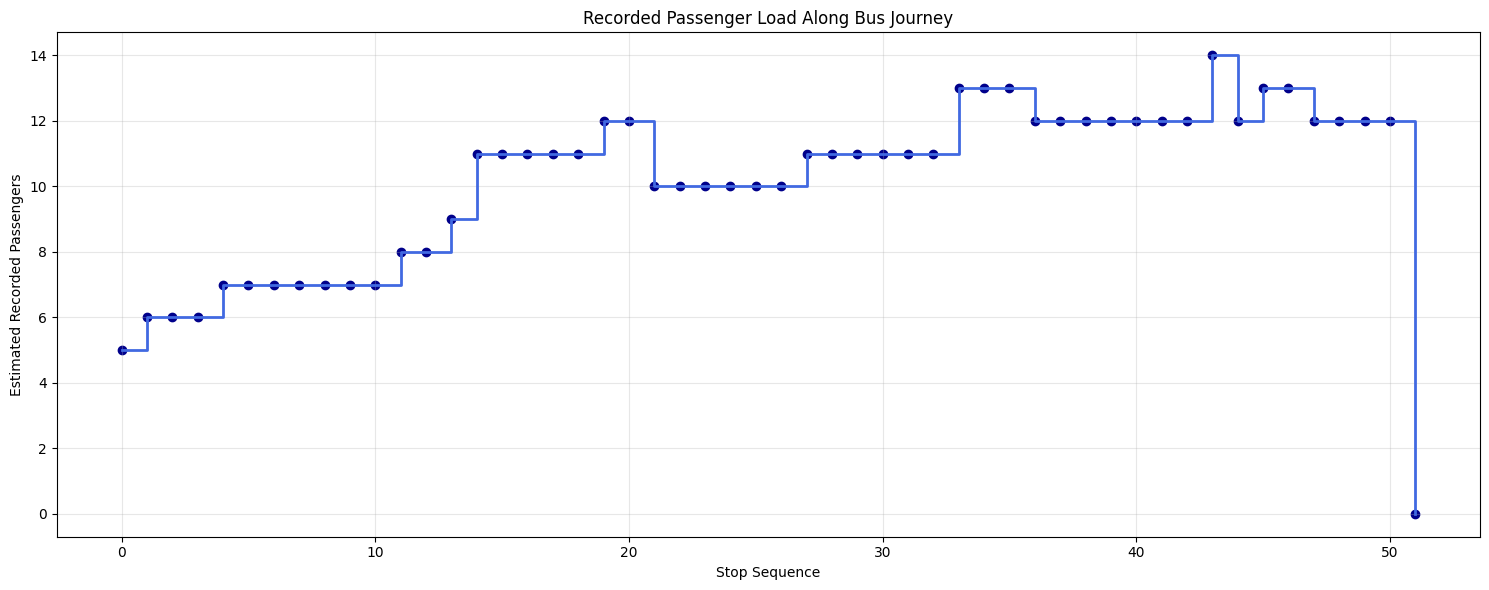

In [42]:
# Cell 40: Visualize passenger load

best_journey = con.execute("""
    SELECT journey_id

    FROM journey_registry

    WHERE vehicles_in_slot = 1

    ORDER BY ticket_records DESC,
             observed_boarding_stops DESC

    LIMIT 1
""").fetchone()

if best_journey is not None:

    journey_example = con.execute("""
        SELECT
            j.stop_sequence,
            s.stop_name,
            j.boarding_passengers,
            j.alighting_passengers,
            j.passenger_load

        FROM journey_stop_load j

        JOIN stop_lookup s
            ON j.stop_id = s.stop_id

        WHERE j.journey_id = ?

        ORDER BY j.stop_sequence

    """, [best_journey[0]]).df()

    display(journey_example)

    plt.figure(figsize=(15, 6))

    plt.step(
        journey_example["stop_sequence"],
        journey_example["passenger_load"],
        where="post",
        color="royalblue",
        linewidth=2
    )

    plt.scatter(
        journey_example["stop_sequence"],
        journey_example["passenger_load"],
        color="darkblue"
    )

    plt.title("Recorded Passenger Load Along Bus Journey")
    plt.xlabel("Stop Sequence")
    plt.ylabel("Estimated Recorded Passengers")
    plt.grid(alpha=0.3)
    plt.tight_layout()
    plt.show()
    plt.close()

else:
    print("No non-conflicting journey available.")

In [43]:
# Cell 41: Historical crowding prediction baseline

con.execute("""
    CREATE OR REPLACE TABLE crowding_profiles AS

    SELECT
        s.route_id,
        s.pattern_id,
        s.stop_sequence,
        s.from_stop_id,
        s.to_stop_id,
        s.is_weekend,
        s.time_slot,

        COUNT(*) AS sample_journeys,

        COUNT(DISTINCT s.travel_date)
            AS observed_days,

        ROUND(AVG(s.recorded_load), 2)
            AS average_load,

        ROUND(MEDIAN(s.recorded_load), 2)
            AS predicted_load,

        ROUND(
            QUANTILE_CONT(s.recorded_load, 0.90),
            2
        ) AS peak_load_p90,

        ROUND(STDDEV_SAMP(s.recorded_load), 2)
            AS load_variability

    FROM segment_load s

    JOIN journey_registry j
        ON s.journey_id = j.journey_id

    WHERE s.travel_date >= DATE '2026-10-01'

        AND s.travel_date < DATE '2026-10-22'

        AND j.vehicles_in_slot = 1

    GROUP BY
        s.route_id,
        s.pattern_id,
        s.stop_sequence,
        s.from_stop_id,
        s.to_stop_id,
        s.is_weekend,
        s.time_slot
""")

print("Historical crowding model created!")

display(con.execute("""
    SELECT *
    FROM crowding_profiles
    ORDER BY sample_journeys DESC
    LIMIT 10
""").df())

display(con.execute("""
    SELECT
        COUNT(*) AS total_profiles,
        COUNT(DISTINCT route_id) AS covered_routes,
        ROUND(AVG(predicted_load), 2)
            AS average_predicted_load

    FROM crowding_profiles
""").df())

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

Historical crowding model created!


,route_id,pattern_id,stop_sequence,from_stop_id,to_stop_id,is_weekend,time_slot,sample_journeys,observed_days,average_load,predicted_load,peak_load_p90,load_variability
0,29,2024,22,431,432,False,15,27,13,2.37,2.0,4.8,1.50
1,29,2024,23,432,473,False,15,27,13,2.37,2.0,4.8,1.50
2,2987,2118,17,2485,2486,False,13,26,15,1.88,1.0,3.5,1.37
3,2987,2118,18,2486,6315,False,13,26,15,1.88,1.0,3.5,1.37
4,1769,705,17,647,648,False,17,26,13,1.62,1.0,3.0,0.98
5,1769,705,18,648,1963,False,17,26,13,1.62,1.0,3.0,0.98
6,1769,705,19,1963,261,False,17,26,13,1.50,1.0,3.0,0.95
7,1769,705,20,261,262,False,17,26,13,1.50,1.0,3.0,0.95
8,29,2024,21,430,431,False,15,26,13,2.27,2.0,5.0,1.56
9,2171,1280,35,7928,2522,False,15,26,13,1.38,1.0,2.5,0.90


,total_profiles,covered_routes,average_predicted_load
0,682803,1616,1.18


In [44]:
# Cell 42: Prediction support classification

con.execute("""
    CREATE OR REPLACE TABLE crowding_model AS

    SELECT
        *,

        CASE

            WHEN sample_journeys >= 20
                AND observed_days >= 7
                THEN 'High'

            WHEN sample_journeys >= 5
                AND observed_days >= 3
                THEN 'Medium'

            ELSE 'Low'

        END AS data_support

    FROM crowding_profiles
""")

display(con.execute("""
    SELECT
        data_support,
        COUNT(*) AS total_profiles,
        ROUND(AVG(predicted_load), 2)
            AS average_predicted_load

    FROM crowding_model

    GROUP BY data_support
""").df())

con.execute("CHECKPOINT")

print("Crowding baseline model saved successfully!")

,data_support,total_profiles,average_predicted_load
0,Low,613607,1.18
1,Medium,69110,1.22
2,High,86,1.30


Crowding baseline model saved successfully!


In [45]:
# Cell 43: Prepare held-out evaluation data

con.execute("""
    CREATE OR REPLACE TABLE evaluation_segments AS

    SELECT
        s.journey_id,
        s.route_id,
        s.pattern_id,
        s.stop_sequence,
        s.from_stop_id,
        s.to_stop_id,
        s.travel_date,
        s.is_weekend,
        s.hour,
        s.time_slot,
        s.recorded_load AS actual_recorded_load,

        CASE
            WHEN s.travel_date < DATE '2026-10-25'
                THEN 'Validation'
            ELSE 'Test'
        END AS dataset_split

    FROM segment_load s

    JOIN journey_registry j
        ON s.journey_id = j.journey_id

    WHERE s.travel_date >= DATE '2026-10-22'
        AND s.travel_date < DATE '2026-11-01'
        AND s.service_date >= DATE '2026-10-22'
        AND j.vehicles_in_slot = 1
""")

display(con.execute("""
    SELECT
        dataset_split,
        COUNT(*) AS segment_observations,
        COUNT(DISTINCT journey_id) AS journeys,
        COUNT(DISTINCT route_id) AS routes,
        MIN(travel_date) AS start_date,
        MAX(travel_date) AS end_date

    FROM evaluation_segments

    GROUP BY dataset_split
""").df())

print("Evaluation dataset prepared successfully!")

,dataset_split,segment_observations,journeys,routes,start_date,end_date
0,Validation,233890,15411,1290,2026-10-22,2026-10-24
1,Test,522214,34714,1440,2026-10-25,2026-10-31


Evaluation dataset prepared successfully!


In [46]:
# Cell 44: Baseline validation predictions

con.execute("""
    CREATE OR REPLACE TABLE validation_predictions AS

    SELECT
        e.*,
        m.predicted_load,
        m.data_support,
        m.sample_journeys,
        m.observed_days

    FROM evaluation_segments e

    LEFT JOIN crowding_model m

        ON e.route_id = m.route_id
        AND e.pattern_id = m.pattern_id
        AND e.stop_sequence = m.stop_sequence
        AND e.from_stop_id = m.from_stop_id
        AND e.to_stop_id = m.to_stop_id
        AND e.is_weekend = m.is_weekend
        AND e.time_slot = m.time_slot

    WHERE e.dataset_split = 'Validation'
""")

display(con.execute("""
    SELECT
        COUNT(*) AS total_observations,

        COUNT(predicted_load) AS predicted_observations,

        COUNT(*) - COUNT(predicted_load)
            AS unavailable_predictions,

        ROUND(
            100.0 * COUNT(predicted_load)
            / NULLIF(COUNT(*), 0), 2
        ) AS prediction_coverage

    FROM validation_predictions
""").df())

print("Baseline validation predictions generated!")

,total_observations,predicted_observations,unavailable_predictions,prediction_coverage
0,233890,179990,53900,76.95


Baseline validation predictions generated!


In [47]:
# Cell 45: Baseline model evaluation

baseline_metrics = con.execute("""
    SELECT
        COUNT(*) AS evaluated_observations,

        ROUND(
            AVG(ABS(
                actual_recorded_load - predicted_load
            )), 4
        ) AS MAE,

        ROUND(
            SQRT(AVG(POWER(
                actual_recorded_load - predicted_load, 2
            ))), 4
        ) AS RMSE,

        ROUND(
            AVG(predicted_load - actual_recorded_load),
            4
        ) AS prediction_bias,

        ROUND(
            100.0 * AVG(
                CASE
                    WHEN ABS(
                        actual_recorded_load - predicted_load
                    ) <= 1
                    THEN 1.0
                    ELSE 0.0
                END
            ), 2
        ) AS within_one_passenger_percentage

    FROM validation_predictions

    WHERE predicted_load IS NOT NULL
""").df()

display(baseline_metrics)

print("Baseline model evaluation completed!")

,evaluated_observations,MAE,RMSE,prediction_bias,within_one_passenger_percentage
0,179990,0.4714,0.908,-0.1313,90.95


Baseline model evaluation completed!


In [48]:
# Cell 46: Support-wise model evaluation

support_metrics = con.execute("""
    SELECT
        data_support,
        COUNT(*) AS evaluated_observations,

        ROUND(
            AVG(ABS(
                actual_recorded_load - predicted_load
            )), 4
        ) AS MAE,

        ROUND(
            SQRT(AVG(POWER(
                actual_recorded_load - predicted_load, 2
            ))), 4
        ) AS RMSE,

        ROUND(AVG(predicted_load), 2)
            AS average_prediction,

        ROUND(AVG(actual_recorded_load), 2)
            AS average_recorded_load

    FROM validation_predictions

    WHERE predicted_load IS NOT NULL

    GROUP BY data_support

    ORDER BY CASE data_support
        WHEN 'High' THEN 1
        WHEN 'Medium' THEN 2
        ELSE 3
    END
""").df()

display(support_metrics)

print("Support-wise evaluation completed!")

,data_support,evaluated_observations,MAE,RMSE,average_prediction,average_recorded_load
0,High,231,0.6039,1.2038,1.27,1.66
1,Medium,55677,0.5581,1.0398,1.26,1.53
2,Low,124082,0.4323,0.8415,1.21,1.27


Support-wise evaluation completed!


In [49]:
# Cell 47: Hourly fallback prediction model

con.execute("""
    CREATE OR REPLACE TABLE hourly_crowding_model AS

    SELECT
        s.route_id,
        s.pattern_id,
        s.stop_sequence,
        s.from_stop_id,
        s.to_stop_id,
        s.is_weekend,
        s.hour,

        COUNT(*) AS sample_journeys,

        COUNT(DISTINCT s.travel_date)
            AS observed_days,

        ROUND(MEDIAN(s.recorded_load), 2)
            AS predicted_load,

        ROUND(AVG(s.recorded_load), 2)
            AS average_load,

        ROUND(
            QUANTILE_CONT(s.recorded_load, 0.90),
            2
        ) AS peak_load_p90

    FROM segment_load s

    JOIN journey_registry j
        ON s.journey_id = j.journey_id

    WHERE s.travel_date >= DATE '2026-10-01'
        AND s.travel_date < DATE '2026-10-22'
        AND j.vehicles_in_slot = 1

    GROUP BY
        s.route_id,
        s.pattern_id,
        s.stop_sequence,
        s.from_stop_id,
        s.to_stop_id,
        s.is_weekend,
        s.hour
""")

display(con.execute("""
    SELECT
        COUNT(*) AS hourly_profiles,

        COUNT(DISTINCT route_id)
            AS covered_routes,

        COUNT_IF(
            sample_journeys >= 5
            AND observed_days >= 3
        ) AS supported_profiles

    FROM hourly_crowding_model
""").df())

print("Hourly fallback model created successfully!")

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

,hourly_profiles,covered_routes,supported_profiles
0,531978,1616,90583.0


Hourly fallback model created successfully!


In [50]:
# Cell 48: Combined hierarchical prediction model

con.execute("""
    CREATE OR REPLACE TABLE improved_validation AS

    SELECT
        v.*,

        h.predicted_load AS hourly_prediction,

        h.sample_journeys AS hourly_samples,

        h.observed_days AS hourly_days,

        CASE
            WHEN v.data_support IN ('High', 'Medium')
                THEN v.predicted_load

            WHEN h.sample_journeys >= 5
                AND h.observed_days >= 3
                THEN h.predicted_load

            WHEN v.predicted_load IS NOT NULL
                THEN v.predicted_load

            ELSE h.predicted_load
        END AS final_prediction,

        CASE
            WHEN v.data_support IN ('High', 'Medium')
                THEN 'Exact 30-minute'

            WHEN h.sample_journeys >= 5
                AND h.observed_days >= 3
                THEN 'Hourly fallback'

            WHEN v.predicted_load IS NOT NULL
                THEN 'Exact low support'

            WHEN h.predicted_load IS NOT NULL
                THEN 'Hourly low support'

            ELSE 'Unavailable'
        END AS prediction_source

    FROM validation_predictions v

    LEFT JOIN hourly_crowding_model h

        ON v.route_id = h.route_id
        AND v.pattern_id = h.pattern_id
        AND v.stop_sequence = h.stop_sequence
        AND v.from_stop_id = h.from_stop_id
        AND v.to_stop_id = h.to_stop_id
        AND v.is_weekend = h.is_weekend
        AND v.hour = h.hour
""")

display(con.execute("""
    SELECT
        prediction_source,
        COUNT(*) AS observations,
        ROUND(AVG(final_prediction), 2)
            AS average_prediction

    FROM improved_validation

    GROUP BY prediction_source

    ORDER BY observations DESC
""").df())

print("Combined prediction model prepared!")

,prediction_source,observations,average_prediction
0,Exact low support,88746,1.20
1,Exact 30-minute,55908,1.26
2,Unavailable,36482,NaN
3,Hourly fallback,36351,1.13
4,Hourly low support,16403,1.19


Combined prediction model prepared!


In [51]:
# Cell 49: Compare baseline and improved model

model_comparison = con.execute("""
    WITH common_predictions AS (

        SELECT *

        FROM improved_validation

        WHERE predicted_load IS NOT NULL
            AND final_prediction IS NOT NULL
    )

    SELECT
        'Baseline' AS model,

        COUNT(*) AS observations,

        ROUND(AVG(ABS(
            actual_recorded_load - predicted_load
        )), 4) AS MAE,

        ROUND(SQRT(AVG(POWER(
            actual_recorded_load - predicted_load, 2
        ))), 4) AS RMSE

    FROM common_predictions

    UNION ALL

    SELECT
        'Improved' AS model,

        COUNT(*) AS observations,

        ROUND(AVG(ABS(
            actual_recorded_load - final_prediction
        )), 4) AS MAE,

        ROUND(SQRT(AVG(POWER(
            actual_recorded_load - final_prediction, 2
        ))), 4) AS RMSE

    FROM common_predictions
""").df()

display(model_comparison)

coverage_comparison = con.execute("""
    SELECT
        COUNT(*) AS total_observations,

        ROUND(
            COUNT(predicted_load) * 100.0
            / NULLIF(COUNT(*), 0), 2
        ) AS baseline_coverage,

        ROUND(
            COUNT(final_prediction) * 100.0
            / NULLIF(COUNT(*), 0), 2
        ) AS improved_coverage,

        ROUND(
            AVG(ABS(
                actual_recorded_load - final_prediction
            )), 4
        ) AS improved_MAE_all_predictions

    FROM improved_validation
""").df()

display(coverage_comparison)

print("Model comparison completed!")

,model,observations,MAE,RMSE
0,Baseline,179990,0.4714,0.9080
1,Improved,179990,0.4574,0.8998


,total_observations,baseline_coverage,improved_coverage,improved_MAE_all_predictions
0,233890,76.95,84.4,0.4531


Model comparison completed!


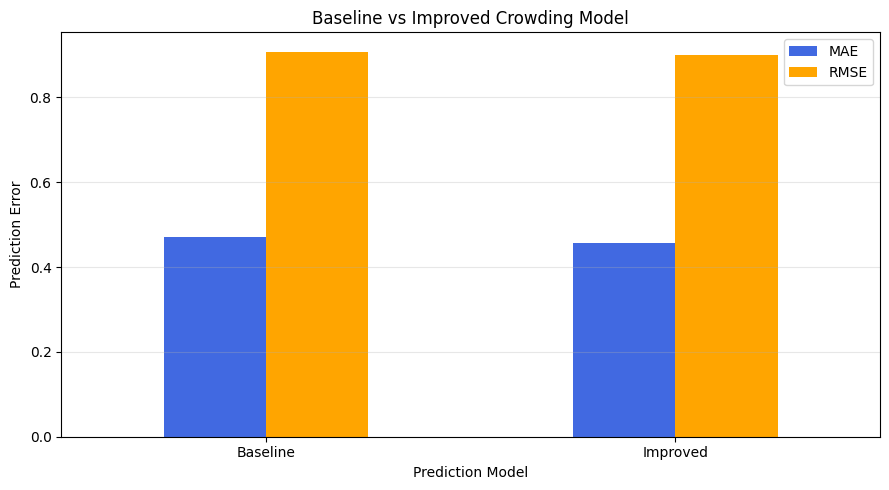

Model validation phase completed!


In [52]:
# Cell 50: Model performance visualization

model_comparison.set_index("model")[
    ["MAE", "RMSE"]
].plot(
    kind="bar",
    figsize=(9, 5),
    color=["royalblue", "orange"]
)

plt.title("Baseline vs Improved Crowding Model")
plt.xlabel("Prediction Model")
plt.ylabel("Prediction Error")
plt.xticks(rotation=0)
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()
plt.close()

con.execute("CHECKPOINT")

print("Model validation phase completed!")

In [53]:
# Cell 51: Final prediction model

con.execute("""
    CREATE OR REPLACE TABLE final_prediction_model AS

    WITH hourly_expanded AS (

        SELECT
            h.*,
            h.hour * 2 + x.half AS time_slot

        FROM hourly_crowding_model h

        CROSS JOIN (
            VALUES (0), (1)
        ) x(half)
    )

    SELECT

        COALESCE(m.route_id, h.route_id) AS route_id,
        COALESCE(m.pattern_id, h.pattern_id) AS pattern_id,
        COALESCE(m.stop_sequence, h.stop_sequence) AS stop_sequence,
        COALESCE(m.from_stop_id, h.from_stop_id) AS from_stop_id,
        COALESCE(m.to_stop_id, h.to_stop_id) AS to_stop_id,
        COALESCE(m.is_weekend, h.is_weekend) AS is_weekend,
        COALESCE(m.time_slot, h.time_slot) AS time_slot,

        m.predicted_load AS baseline_prediction,

        CASE
            WHEN m.data_support IN ('High', 'Medium')
                THEN m.predicted_load
            WHEN h.sample_journeys >= 5
                AND h.observed_days >= 3
                THEN h.predicted_load
            ELSE COALESCE(m.predicted_load, h.predicted_load)
        END AS predicted_load,

        CASE
            WHEN m.data_support IN ('High', 'Medium')
                THEN 'Exact 30-minute'
            WHEN h.sample_journeys >= 5
                AND h.observed_days >= 3
                THEN 'Hourly fallback'
            WHEN m.predicted_load IS NOT NULL
                THEN 'Exact low support'
            ELSE 'Hourly low support'
        END AS prediction_source,

        CASE
            WHEN m.data_support IN ('High', 'Medium')
                THEN m.sample_journeys
            WHEN h.sample_journeys >= 5
                AND h.observed_days >= 3
                THEN h.sample_journeys
            ELSE COALESCE(m.sample_journeys, h.sample_journeys)
        END AS sample_journeys,

        CASE
            WHEN m.data_support IN ('High', 'Medium')
                THEN m.observed_days
            WHEN h.sample_journeys >= 5
                AND h.observed_days >= 3
                THEN h.observed_days
            ELSE COALESCE(m.observed_days, h.observed_days)
        END AS observed_days,

        CASE
            WHEN m.data_support IN ('High', 'Medium')
                THEN m.peak_load_p90
            WHEN h.sample_journeys >= 5
                AND h.observed_days >= 3
                THEN h.peak_load_p90
            ELSE COALESCE(m.peak_load_p90, h.peak_load_p90)
        END AS peak_load_p90

    FROM crowding_model m

    FULL OUTER JOIN hourly_expanded h

        ON m.route_id = h.route_id
        AND m.pattern_id = h.pattern_id
        AND m.stop_sequence = h.stop_sequence
        AND m.from_stop_id = h.from_stop_id
        AND m.to_stop_id = h.to_stop_id
        AND m.is_weekend = h.is_weekend
        AND m.time_slot = h.time_slot
""")

display(con.execute("""
    SELECT
        COUNT(*) AS total_profiles,
        COUNT(DISTINCT route_id) AS covered_routes,
        COUNT(predicted_load) AS available_predictions
    FROM final_prediction_model
""").df())

print("Final prediction model created successfully!")

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

,total_profiles,covered_routes,available_predictions
0,1063956,1616,1063956


Final prediction model created successfully!


In [54]:
# Cell 52: Unseen test data prediction

con.execute("""
    CREATE OR REPLACE TABLE final_test_predictions AS

    SELECT
        e.*,
        m.baseline_prediction,
        m.predicted_load,
        m.prediction_source,
        m.sample_journeys,
        m.observed_days

    FROM evaluation_segments e

    LEFT JOIN final_prediction_model m

        ON e.route_id = m.route_id
        AND e.pattern_id = m.pattern_id
        AND e.stop_sequence = m.stop_sequence
        AND e.from_stop_id = m.from_stop_id
        AND e.to_stop_id = m.to_stop_id
        AND e.is_weekend = m.is_weekend
        AND e.time_slot = m.time_slot

    WHERE e.dataset_split = 'Test'
""")

display(con.execute("""
    SELECT
        COUNT(*) AS total_test_observations,

        COUNT(predicted_load)
            AS successful_predictions,

        COUNT(*) - COUNT(predicted_load)
            AS unavailable_predictions,

        ROUND(
            100.0 * COUNT(predicted_load)
            / NULLIF(COUNT(*), 0), 2
        ) AS test_coverage_percentage

    FROM final_test_predictions
""").df())

assert con.execute("""
    SELECT COUNT(*) FROM final_test_predictions
""").fetchone()[0] == con.execute("""
    SELECT COUNT(*) FROM evaluation_segments
    WHERE dataset_split = 'Test'
""").fetchone()[0], "Unexpected duplicate predictions"

print("Final test predictions generated!")

,total_test_observations,successful_predictions,unavailable_predictions,test_coverage_percentage
0,522214,442098,80116,84.66


Final test predictions generated!


In [55]:
# Cell 53: Final test evaluation

final_test_metrics = con.execute("""
    SELECT
        COUNT(*) AS total_observations,

        COUNT(predicted_load)
            AS evaluated_observations,

        ROUND(
            AVG(ABS(
                actual_recorded_load - predicted_load
            )), 4
        ) AS MAE,

        ROUND(
            SQRT(AVG(POWER(
                actual_recorded_load - predicted_load, 2
            ))), 4
        ) AS RMSE,

        ROUND(
            AVG(predicted_load - actual_recorded_load),
            4
        ) AS prediction_bias,

        ROUND(
            100.0 * AVG(
                CASE
                    WHEN predicted_load IS NULL THEN NULL
                    WHEN ABS(
                        actual_recorded_load - predicted_load
                    ) <= 1 THEN 1.0
                    ELSE 0.0
                END
            ), 2
        ) AS within_one_passenger_percentage,

        ROUND(
            100.0 * COUNT(predicted_load)
            / NULLIF(COUNT(*), 0), 2
        ) AS coverage_percentage

    FROM final_test_predictions
""").df()

display(final_test_metrics)

print("Final test evaluation completed!")

,total_observations,evaluated_observations,MAE,RMSE,prediction_bias,within_one_passenger_percentage,coverage_percentage
0,522214,442098,0.4686,0.9216,-0.1388,90.97,84.66


Final test evaluation completed!


,model,observations,MAE,RMSE
0,Baseline,404017,0.4895,0.9415
1,Final Model,404017,0.4766,0.9346


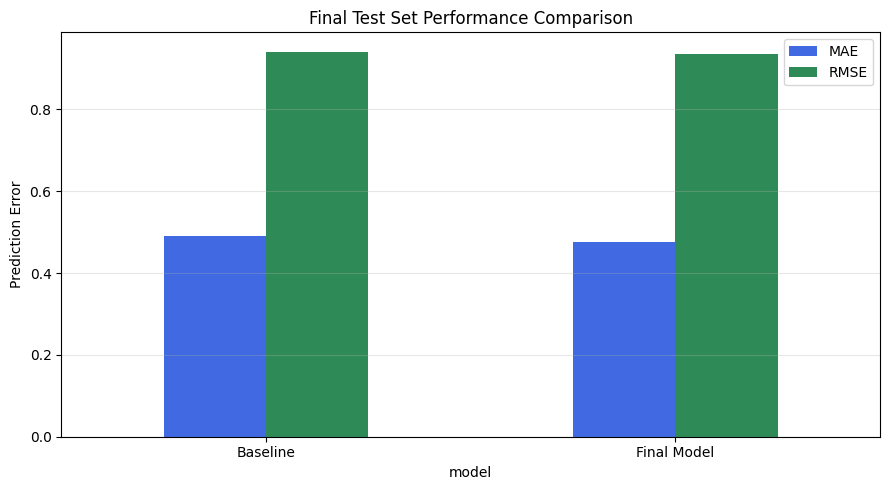

In [56]:
# Cell 54: Fair test-set model comparison

final_comparison = con.execute("""
    WITH common AS (

        SELECT *
        FROM final_test_predictions

        WHERE baseline_prediction IS NOT NULL
            AND predicted_load IS NOT NULL
    )

    SELECT
        'Baseline' AS model,
        COUNT(*) AS observations,

        ROUND(AVG(ABS(
            actual_recorded_load - baseline_prediction
        )), 4) AS MAE,

        ROUND(SQRT(AVG(POWER(
            actual_recorded_load - baseline_prediction, 2
        ))), 4) AS RMSE

    FROM common

    UNION ALL

    SELECT
        'Final Model' AS model,
        COUNT(*) AS observations,

        ROUND(AVG(ABS(
            actual_recorded_load - predicted_load
        )), 4) AS MAE,

        ROUND(SQRT(AVG(POWER(
            actual_recorded_load - predicted_load, 2
        ))), 4) AS RMSE

    FROM common
""").df()

display(final_comparison)

final_comparison.set_index("model")[
    ["MAE", "RMSE"]
].plot(
    kind="bar",
    figsize=(9, 5),
    color=["royalblue", "seagreen"]
)

plt.title("Final Test Set Performance Comparison")
plt.ylabel("Prediction Error")
plt.xticks(rotation=0)
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()
plt.close()

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

,week_number,segment_observations,observed_days,observed_journeys,average_recorded_load,median_recorded_load,p90_recorded_load
0,1,494347,7,32430,1.293,1.0,2.0
1,2,499045,7,33536,1.305,1.0,2.0
2,3,504358,7,33751,1.311,1.0,2.0
3,4,532849,7,35228,1.316,1.0,2.0
4,5,223339,3,14906,1.308,1.0,2.0


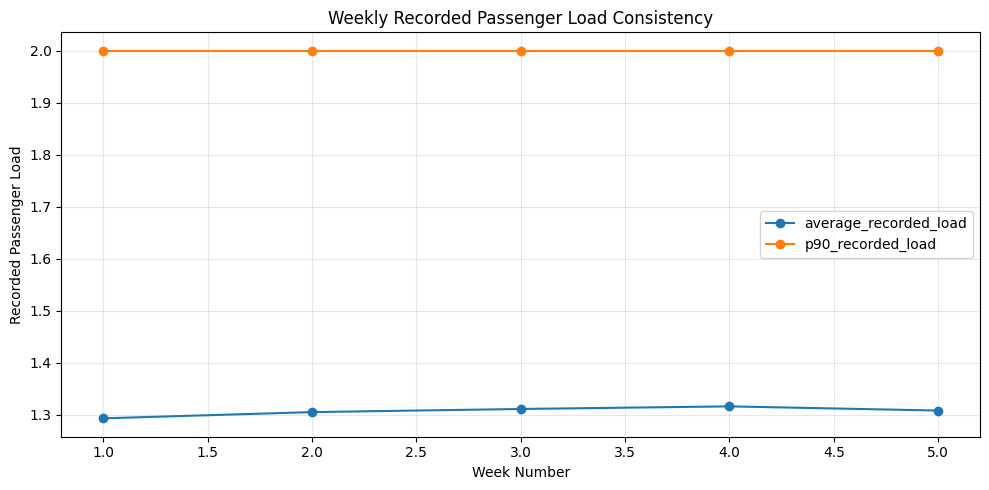

In [57]:
# Cell 55: Weekly consistency analysis

weekly_analysis = con.execute("""
    SELECT

        CAST(
            FLOOR(
                DATE_DIFF(
                    'day',
                    DATE '2026-10-01',
                    s.travel_date
                ) / 7.0
            ) AS INTEGER
        ) + 1 AS week_number,

        COUNT(*) AS segment_observations,

        COUNT(DISTINCT s.travel_date)
            AS observed_days,

        COUNT(DISTINCT s.journey_id)
            AS observed_journeys,

        ROUND(AVG(s.recorded_load), 3)
            AS average_recorded_load,

        ROUND(MEDIAN(s.recorded_load), 3)
            AS median_recorded_load,

        ROUND(
            QUANTILE_CONT(s.recorded_load, 0.90), 3
        ) AS p90_recorded_load

    FROM segment_load s

    JOIN journey_registry j
        ON s.journey_id = j.journey_id

    WHERE s.travel_date >= DATE '2026-10-01'
        AND s.travel_date < DATE '2026-11-01'
        AND j.vehicles_in_slot = 1

    GROUP BY week_number
    ORDER BY week_number
""").df()

display(weekly_analysis)

weekly_analysis.set_index("week_number")[
    ["average_recorded_load", "p90_recorded_load"]
].plot(
    kind="line",
    marker="o",
    figsize=(10, 5)
)

plt.title("Weekly Recorded Passenger Load Consistency")
plt.xlabel("Week Number")
plt.ylabel("Recorded Passenger Load")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()
plt.close()

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

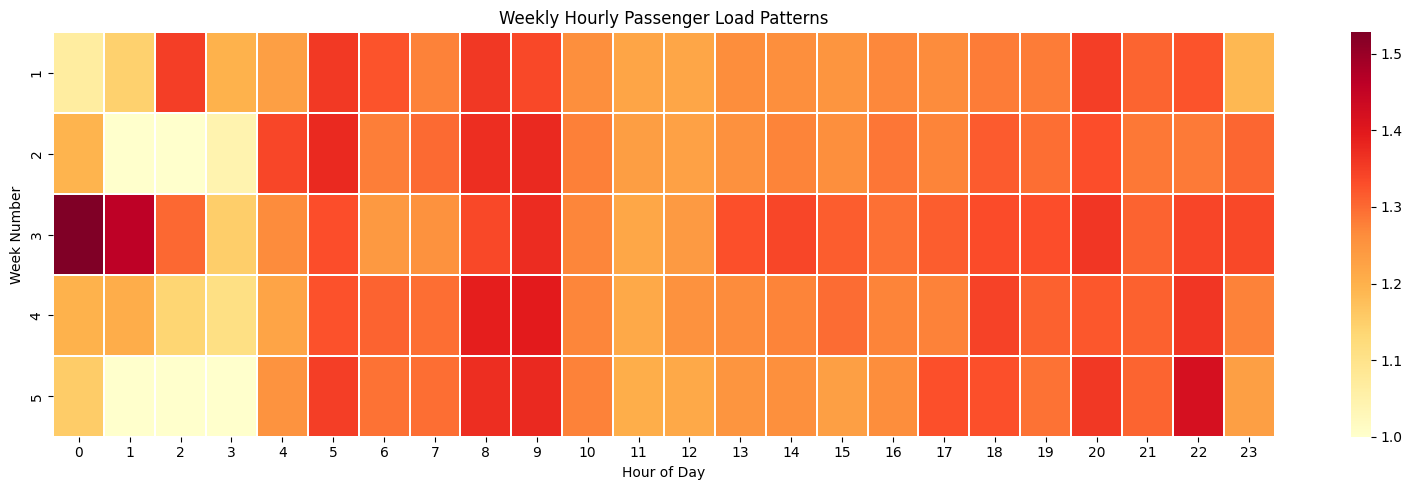

In [58]:
# Cell 56: Weekly hourly crowding patterns

weekly_hourly = con.execute("""
    SELECT

        CAST(
            FLOOR(
                DATE_DIFF(
                    'day',
                    DATE '2026-10-01',
                    s.travel_date
                ) / 7.0
            ) AS INTEGER
        ) + 1 AS week_number,

        s.hour,

        ROUND(AVG(s.recorded_load), 3)
            AS average_load

    FROM segment_load s

    JOIN journey_registry j
        ON s.journey_id = j.journey_id

    WHERE s.travel_date >= DATE '2026-10-01'
        AND s.travel_date < DATE '2026-11-01'
        AND j.vehicles_in_slot = 1

    GROUP BY week_number, s.hour
    ORDER BY week_number, s.hour
""").df()

weekly_heatmap = weekly_hourly.pivot(
    index="week_number",
    columns="hour",
    values="average_load"
)

plt.figure(figsize=(16, 5))

sns.heatmap(
    weekly_heatmap,
    cmap="YlOrRd",
    linewidths=0.2
)

plt.title("Weekly Hourly Passenger Load Patterns")
plt.xlabel("Hour of Day")
plt.ylabel("Week Number")
plt.tight_layout()
plt.show()
plt.close()

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

,day_type,period,segment_observations,average_load,peak_load_p90
0,Weekday,Evening Peak,425311,1.316,2.0
1,Weekday,Morning Peak,673746,1.347,2.0
2,Weekday,Other Hours,585883,1.266,2.0
3,Weekend,Evening Peak,138428,1.303,2.0
4,Weekend,Morning Peak,206818,1.287,2.0
5,Weekend,Other Hours,223752,1.293,2.0


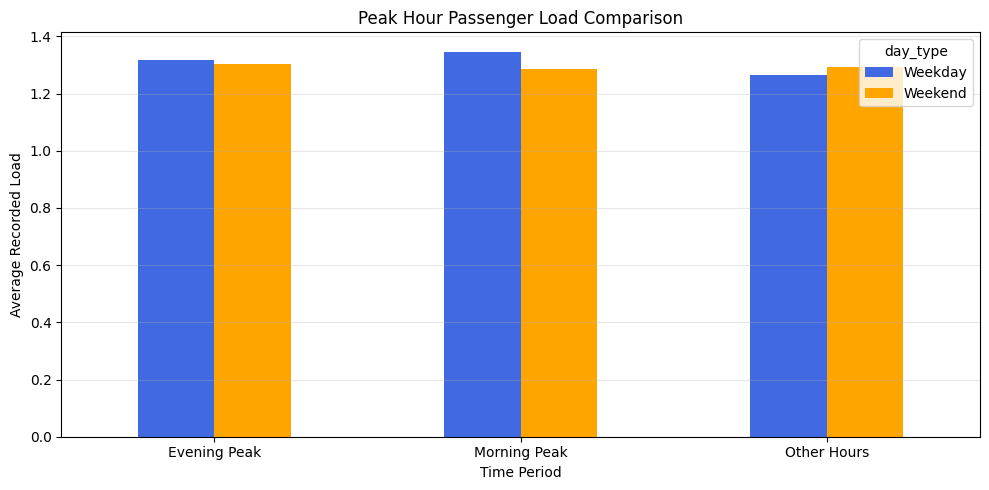

Peak-hour validation completed!


In [59]:
# Cell 57: Peak-hour load analysis

peak_analysis = con.execute("""
    SELECT

        CASE
            WHEN s.is_weekend THEN 'Weekend'
            ELSE 'Weekday'
        END AS day_type,

        CASE
            WHEN s.hour BETWEEN 7 AND 10
                THEN 'Morning Peak'
            WHEN s.hour BETWEEN 17 AND 20
                THEN 'Evening Peak'
            ELSE 'Other Hours'
        END AS period,

        COUNT(*) AS segment_observations,

        ROUND(AVG(s.recorded_load), 3)
            AS average_load,

        ROUND(
            QUANTILE_CONT(s.recorded_load, 0.90),
            3
        ) AS peak_load_p90

    FROM segment_load s

    JOIN journey_registry j
        ON s.journey_id = j.journey_id

    WHERE j.vehicles_in_slot = 1
        AND s.travel_date >= DATE '2026-10-01'
        AND s.travel_date < DATE '2026-11-01'

    GROUP BY day_type, period
    ORDER BY day_type, period
""").df()

display(peak_analysis)

peak_analysis.pivot(
    index="period",
    columns="day_type",
    values="average_load"
).plot(
    kind="bar",
    figsize=(10, 5),
    color=["royalblue", "orange"]
)

plt.title("Peak Hour Passenger Load Comparison")
plt.ylabel("Average Recorded Load")
plt.xlabel("Time Period")
plt.xticks(rotation=0)
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()
plt.close()

con.execute("CHECKPOINT")

print("Peak-hour validation completed!")

In [60]:
# Cell 58: Relative crowding thresholds

con.execute("""
    CREATE OR REPLACE TABLE crowding_thresholds AS

    SELECT
        s.route_id,
        s.pattern_id,
        s.stop_sequence,
        s.from_stop_id,
        s.to_stop_id,

        COUNT(*) AS reference_samples,

        COUNT(DISTINCT s.travel_date)
            AS reference_days,

        QUANTILE_CONT(s.recorded_load, 0.25)
            AS lower_threshold,

        QUANTILE_CONT(s.recorded_load, 0.75)
            AS upper_threshold

    FROM segment_load s

    JOIN journey_registry j
        ON s.journey_id = j.journey_id

    WHERE s.travel_date >= DATE '2026-10-01'
        AND s.travel_date < DATE '2026-10-22'
        AND j.vehicles_in_slot = 1

    GROUP BY
        s.route_id,
        s.pattern_id,
        s.stop_sequence,
        s.from_stop_id,
        s.to_stop_id
""")

display(con.execute("""
    SELECT *
    FROM crowding_thresholds
    ORDER BY reference_samples DESC
    LIMIT 10
""").df())

print("Crowding thresholds generated successfully!")

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

,route_id,pattern_id,stop_sequence,from_stop_id,to_stop_id,reference_samples,reference_days,lower_threshold,upper_threshold
0,1769,705,18,648,1963,380,21,1.0,2.0
1,1769,705,17,647,648,377,21,1.0,2.0
2,1769,705,16,646,647,375,21,1.0,2.0
3,1769,705,19,1963,261,367,21,1.0,2.0
4,1769,705,20,261,262,367,21,1.0,2.0
5,1769,705,12,2037,9735,363,21,1.0,2.0
6,1769,705,13,9735,1472,355,21,1.0,2.0
7,1769,705,15,7641,646,355,21,1.0,2.0
8,1769,705,14,1472,7641,354,21,1.0,2.0
9,1769,705,11,2036,2037,352,21,1.0,2.0


Crowding thresholds generated successfully!


In [61]:
# Cell 59: Final crowding classification

con.execute("""
    CREATE OR REPLACE TABLE final_crowding_output AS

    SELECT
        m.*,

        t.lower_threshold,
        t.upper_threshold,
        t.reference_samples,

        CASE
            WHEN m.sample_journeys >= 20
                AND m.observed_days >= 7
                THEN 'High'

            WHEN m.sample_journeys >= 5
                AND m.observed_days >= 3
                THEN 'Medium'

            ELSE 'Low'
        END AS data_support,

        CASE
            WHEN m.predicted_load IS NULL
                OR m.sample_journeys < 5
                OR m.observed_days < 3
                OR t.reference_samples IS NULL
                OR t.reference_samples < 20
                OR t.reference_days < 5
                THEN 'Insufficient Data'

            WHEN m.predicted_load < t.lower_threshold
                THEN 'Low'

            WHEN m.predicted_load > t.upper_threshold
                THEN 'High'

            ELSE 'Moderate'
        END AS crowding_level

    FROM final_prediction_model m

    LEFT JOIN crowding_thresholds t

        ON m.route_id = t.route_id
        AND m.pattern_id = t.pattern_id
        AND m.stop_sequence = t.stop_sequence
        AND m.from_stop_id = t.from_stop_id
        AND m.to_stop_id = t.to_stop_id
""")

display(con.execute("""
    SELECT
        crowding_level,
        COUNT(*) AS total_profiles,
        ROUND(AVG(predicted_load), 3)
            AS average_predicted_load

    FROM final_crowding_output

    GROUP BY crowding_level
    ORDER BY total_profiles DESC
""").df())

print("Final crowding classification completed!")

,crowding_level,total_profiles,average_predicted_load
0,Insufficient Data,894656,1.170
1,Moderate,159982,1.110
2,High,8747,2.362
3,Low,571,0.212


Final crowding classification completed!


In [62]:
# Cell 60: Final output validation

output_validation = con.execute("""
    SELECT
        COUNT(*) AS total_profiles,

        COUNT(DISTINCT route_id)
            AS covered_routes,

        COUNT_IF(predicted_load < 0)
            AS negative_predictions,

        COUNT_IF(crowding_level IS NULL)
            AS missing_classifications,

        COUNT_IF(crowding_level = 'Insufficient Data')
            AS insufficient_profiles,

        COUNT_IF(time_slot < 0 OR time_slot > 47)
            AS invalid_time_slots

    FROM final_crowding_output
""").df()

display(output_validation)

assert output_validation.loc[0, "negative_predictions"] == 0
assert output_validation.loc[0, "missing_classifications"] == 0
assert output_validation.loc[0, "invalid_time_slots"] == 0

assert output_validation.loc[0, "total_profiles"] == con.execute("""
    SELECT COUNT(*) FROM final_prediction_model
""").fetchone()[0]

print("Final output validation passed!")

,total_profiles,covered_routes,negative_predictions,missing_classifications,insufficient_profiles,invalid_time_slots
0,1063956,1616,0.0,0.0,894656.0,0.0


Final output validation passed!


In [63]:
# Cell 61: Route analytics

con.execute("""
    CREATE OR REPLACE TABLE route_analytics AS

    SELECT
        m.route_id,
        r.route_short_name AS route_name,

        m.is_weekend,
        m.time_slot,

        COUNT(*) AS segment_profiles,

        ROUND(AVG(m.predicted_load), 3)
            AS average_recorded_load,

        MAX(m.predicted_load)
            AS maximum_recorded_load,

        COUNT_IF(m.crowding_level = 'Low')
            AS low_crowding_segments,

        COUNT_IF(m.crowding_level = 'Moderate')
            AS moderate_crowding_segments,

        COUNT_IF(m.crowding_level = 'High')
            AS high_crowding_segments,

        COUNT_IF(m.crowding_level = 'Insufficient Data')
            AS insufficient_data_segments

    FROM final_crowding_output m

    JOIN gtfs_routes r
        ON m.route_id = r.route_id

    GROUP BY
        m.route_id,
        r.route_short_name,
        m.is_weekend,
        m.time_slot
""")

display(con.execute("""
    SELECT *
    FROM route_analytics
    ORDER BY high_crowding_segments DESC
    LIMIT 10
""").df())

print("Operator analytics prepared successfully!")

,route_id,route_name,is_weekend,time_slot,segment_profiles,average_recorded_load,maximum_recorded_load,low_crowding_segments,moderate_crowding_segments,high_crowding_segments,insufficient_data_segments
0,1010,874EDOWN,False,18,60,2.475,5.0,0.0,3.0,31.0,26.0
1,51,113DOWN,False,20,65,1.615,3.0,0.0,17.0,31.0,17.0
2,1010,874EDOWN,False,19,60,2.317,4.0,0.0,4.0,30.0,26.0
3,1112,929DOWN,False,20,45,1.778,2.0,0.0,5.0,30.0,10.0
4,1112,929DOWN,False,21,45,1.756,2.0,0.0,5.0,30.0,10.0
5,2659,DW-3DOWN,False,38,58,1.940,3.0,0.0,29.0,29.0,0.0
6,2203,729DOWN,False,26,61,1.984,3.0,0.0,16.0,28.0,17.0
7,2263,801-IND-IGIUP,False,18,58,2.853,6.0,0.0,31.0,27.0,0.0
8,1010,874EDOWN,False,43,72,1.882,4.0,0.0,13.0,27.0,32.0
9,51,113DOWN,False,21,65,1.408,2.0,0.0,23.0,25.0,17.0


Operator analytics prepared successfully!


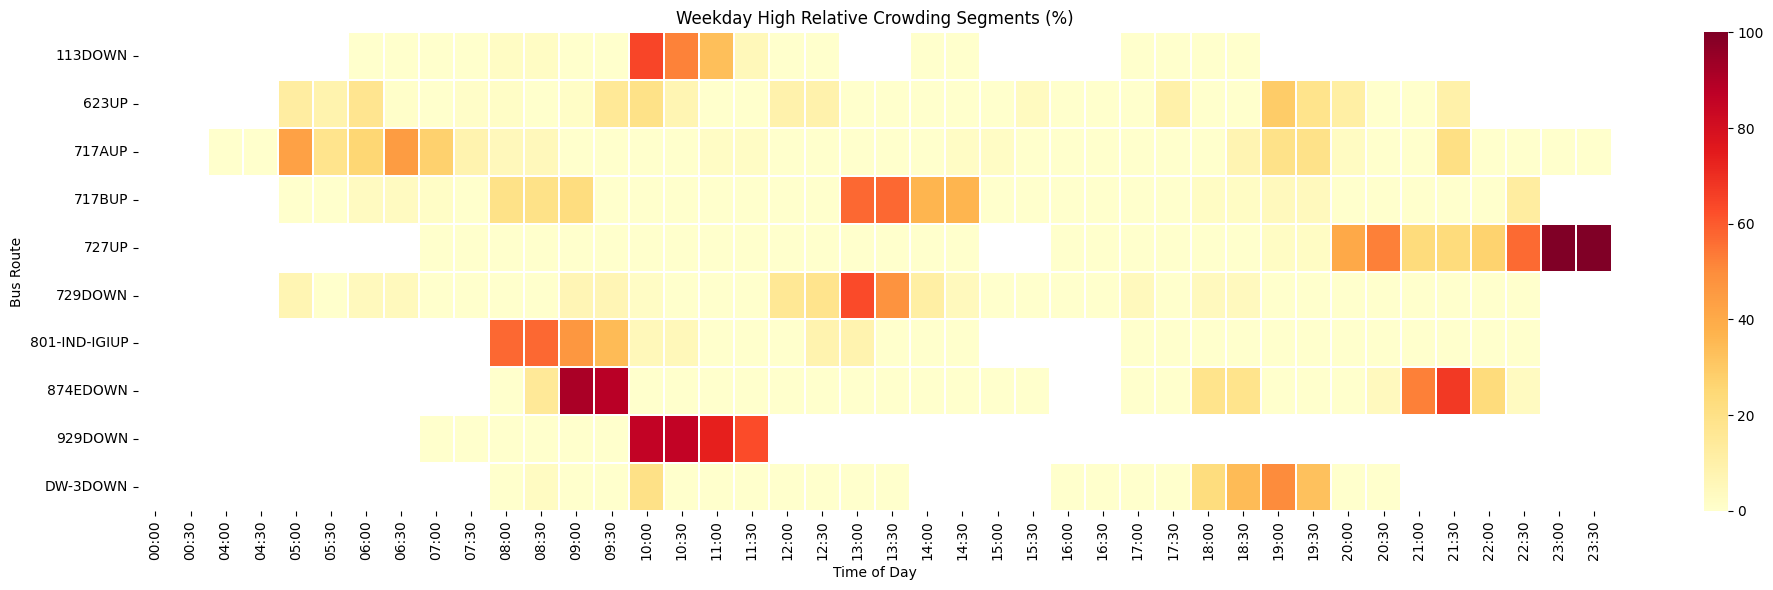

In [64]:
# Cell 62: Final crowding heatmap

heatmap_data = con.execute("""
    WITH selected_routes AS (

        SELECT
            route_name

        FROM route_analytics

        WHERE is_weekend = FALSE

        GROUP BY route_name

        ORDER BY SUM(high_crowding_segments) DESC

        LIMIT 10
    )

    SELECT
        a.route_name,
        a.time_slot,

        100.0 * SUM(a.high_crowding_segments)
        / NULLIF(
            SUM(
                a.segment_profiles
                - a.insufficient_data_segments
            ), 0
        ) AS high_crowding_percentage

    FROM route_analytics a

    JOIN selected_routes r
        ON a.route_name = r.route_name

    WHERE a.is_weekend = FALSE

    GROUP BY a.route_name, a.time_slot
""").df()

if not heatmap_data.empty:

    heatmap_final = heatmap_data.pivot(
        index="route_name",
        columns="time_slot",
        values="high_crowding_percentage"
    )

    heatmap_final.columns = [
        f"{int(x)//2:02d}:{(int(x)%2)*30:02d}"
        for x in heatmap_final.columns
    ]

    plt.figure(figsize=(20, 6))

    sns.heatmap(
        heatmap_final,
        cmap="YlOrRd",
        vmin=0,
        vmax=100,
        linewidths=0.2
    )

    plt.title("Weekday High Relative Crowding Segments (%)")
    plt.xlabel("Time of Day")
    plt.ylabel("Bus Route")
    plt.tight_layout()
    plt.show()
    plt.close()

else:
    print("No heatmap data available.")

In [65]:
# Cell 63: Export processed model files

from pathlib import Path

EXPORT_PATH = Path("/content/crowdroute_export")
EXPORT_PATH.mkdir(exist_ok=True)

export_tables = {
    "final_crowding_output": "crowding_model.parquet",
    "route_analytics": "route_analytics.parquet",
    "route_stop_sequence": "route_stop_sequence.parquet",
    "stop_lookup": "stops.parquet",
    "route_lookup": "route_lookup.parquet",
    "valid_trip_clock": "trip_schedule.parquet",
    "gtfs_routes": "routes.parquet",
    "gtfs_calendar": "calendar.parquet"
}

for table, filename in export_tables.items():

    path = EXPORT_PATH / filename

    con.execute(f"""
        COPY (
            SELECT * FROM {table}
        )
        TO '{path}'
        (
            FORMAT PARQUET,
            COMPRESSION ZSTD
        )
    """)

    print(
        filename,
        "|",
        round(path.stat().st_size / 1024**2, 2),
        "MB"
    )

print("\nAll model files exported successfully!")

crowding_model.parquet | 6.32 MB
route_analytics.parquet | 0.35 MB
route_stop_sequence.parquet | 0.73 MB
stops.parquet | 0.22 MB
route_lookup.parquet | 0.03 MB
trip_schedule.parquet | 9.84 MB
routes.parquet | 0.08 MB
calendar.parquet | 0.0 MB

All model files exported successfully!


In [66]:
# Cell 64: Export evaluation and metadata

import json

final_test_metrics.to_csv(
    EXPORT_PATH / "test_metrics.csv",
    index=False
)

final_comparison.to_csv(
    EXPORT_PATH / "model_comparison.csv",
    index=False
)

weekly_analysis.to_csv(
    EXPORT_PATH / "weekly_analysis.csv",
    index=False
)

peak_analysis.to_csv(
    EXPORT_PATH / "peak_analysis.csv",
    index=False
)

metadata = {
    "project": "CrowdRoute Delhi",
    "model_type": "Historical Median with Hourly Fallback",
    "version": "1.0",
    "timezone": "Asia/Kolkata",
    "training_period": "2026-10-01 to 2026-10-21",
    "validation_period": "2026-10-22 to 2026-10-24",
    "testing_period": "2026-10-25 to 2026-10-31",
    "time_slot_minutes": 30,
    "total_ticket_records": int(len(df)),
    "final_profiles": int(con.execute("""
        SELECT COUNT(*) FROM final_crowding_output
    """).fetchone()[0]),
    "crowding_type": "Relative historical crowding",
    "minimum_profile_samples": 5,
    "minimum_profile_days": 3,
    "minimum_reference_samples": 20,
    "minimum_reference_days": 5,
    "actual_occupancy_validated": False,
    "capacity_calibration_available": False,
    "limitations": [
        "Missing vehicle numbers",
        "Unmatched ticket stops",
        "Partial ticket assignment coverage",
        "Schedule based trip reconstruction",
        "Unrecorded passengers and pass holders",
        "Assumed alighting at ticket destination",
        "Unknown actual bus capacity",
        "Relative crowding is not seat availability"
    ]
}

with open(
    EXPORT_PATH / "model_metadata.json",
    "w",
    encoding="utf-8"
) as f:
    json.dump(metadata, f, indent=4)

print("Evaluation reports and metadata exported!")

Evaluation reports and metadata exported!


In [67]:
# Cell 65: Export verification

export_summary = []

for file in sorted(EXPORT_PATH.iterdir()):

    if file.is_file():

        export_summary.append({
            "File": file.name,
            "Size_MB": round(
                file.stat().st_size / 1024**2, 3
            )
        })

display(pd.DataFrame(export_summary))

for table, filename in export_tables.items():

    path = EXPORT_PATH / filename

    exported_count = con.execute(f"""
        SELECT COUNT(*)
        FROM read_parquet('{path}')
    """).fetchone()[0]

    original_count = con.execute(f"""
        SELECT COUNT(*) FROM {table}
    """).fetchone()[0]

    assert exported_count == original_count, (
        f"Export row count mismatch: {filename}"
    )

    print(f"{filename}: Verified ({exported_count} rows)")

con.execute("CHECKPOINT")

print("\nAll exported model files verified!")

,File,Size_MB
0,calendar.parquet,0.002
1,crowding_model.parquet,6.324
2,model_comparison.csv,0.000
3,model_metadata.json,0.001
4,peak_analysis.csv,0.000
5,route_analytics.parquet,0.351
6,route_lookup.parquet,0.027
7,route_stop_sequence.parquet,0.726
8,routes.parquet,0.078
9,stops.parquet,0.222


crowding_model.parquet: Verified (1063956 rows)
route_analytics.parquet: Verified (50318 rows)
route_stop_sequence.parquet: Verified (109660 rows)
stops.parquet: Verified (6862 rows)
route_lookup.parquet: Verified (1980 rows)
trip_schedule.parquet: Verified (2737136 rows)
routes.parquet: Verified (2574 rows)
calendar.parquet: Verified (1 rows)

All exported model files verified!


In [68]:
# Cell 66: Create final model package

import shutil
from google.colab import files

zip_path = shutil.make_archive(
    "/content/CrowdRoute_Delhi_Model",
    "zip",
    root_dir=str(EXPORT_PATH)
)

print("Model package created successfully!")

print(
    "ZIP Size:",
    round(Path(zip_path).stat().st_size / 1024**2, 2),
    "MB"
)

files.download(zip_path)

Model package created successfully!
ZIP Size: 17.39 MB


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>